In [1]:
## GROUP LEVEL DATA - task vs rest 

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Enable interactive plotting (optional)
%matplotlib qt

# Load combined CSV file
file = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\power_analysis_combined.csv"
df = pd.read_csv(file)

# Optional: Filter to HbO only (if applicable)
if 'type' in df.columns:
    df = df[df['type'].str.lower() == 'hbo']

# --- Drop Rows with Detector in {16–23} ---
bad_detectors = {16, 17, 18, 19, 20, 21, 22, 23}
df = df[~df['detector'].isin(bad_detectors)]

# --- Drop Specific Source-Detector Pairs ---
df = df[~((df['source'] == 14) & (df['detector'] == 13))]
df = df[~((df['source'] == 16) & (df['detector'] == 12))]


# --- Compute summary statistics per block count ---
summary_df = df.groupby('n_blocks').agg(
    mean_tstat=('tstat', 'mean'),
    median_tstat=('tstat', 'median'),
    prop_sig_p=('q', lambda x: (x < 0.05).mean()),
    var_tstat=('tstat', 'var'),
    std_tstat=('tstat', 'std'),
    n_channels=('tstat', 'count'),
    mean_beta=('beta', 'mean'),
    mean_se=('se', 'mean'),
    beta_sem=('beta', lambda x: stats.sem(x, nan_policy='omit')),
    se_sem=('se', lambda x: stats.sem(x, nan_policy='omit'))
).reset_index()

# --- Compute 95% CIs and bounds ---
t_critical = stats.t.ppf(0.975, df=summary_df['n_channels'] - 1)

summary_df['beta_ci95'] = summary_df['beta_sem'] * t_critical
summary_df['se_ci95'] = summary_df['se_sem'] * t_critical

summary_df['beta_ci_lower'] = summary_df['mean_beta'] - summary_df['beta_ci95']
summary_df['beta_ci_upper'] = summary_df['mean_beta'] + summary_df['beta_ci95']

summary_df['se_ci_lower'] = summary_df['mean_se'] - summary_df['se_ci95']
summary_df['se_ci_upper'] = summary_df['mean_se'] + summary_df['se_ci95']

# Optional: rename for clarity
tvr_summary = summary_df

# --- Print final summary with CI bounds ---
print(tvr_summary)



   n_blocks  mean_tstat  median_tstat  prop_sig_p  var_tstat  std_tstat  \
0         3    2.218726      2.187025    0.361111   3.946174   1.986498   
1         6    2.157983      2.179155    0.444444   4.768197   2.183620   
2         9    1.775159      1.616950    0.472222   5.544829   2.354746   
3        12    1.982397      2.138603    0.444444   4.595166   2.143634   
4        15    1.518159      1.964913    0.500000   5.756562   2.399284   
5        18    2.016603      2.110885    0.527778   6.086977   2.467180   

   n_channels  mean_beta   mean_se  beta_sem    se_sem  beta_ci95   se_ci95  \
0          36   0.970079  0.412670  0.161206  0.011415   0.327266  0.023174   
1          36   0.653520  0.293079  0.119131  0.009446   0.241850  0.019176   
2          36   0.432777  0.245118  0.105790  0.008444   0.214765  0.017142   
3          36   0.471142  0.231997  0.095142  0.008117   0.193149  0.016478   
4          36   0.338316  0.218688  0.096584  0.007897   0.196075  0.016032   


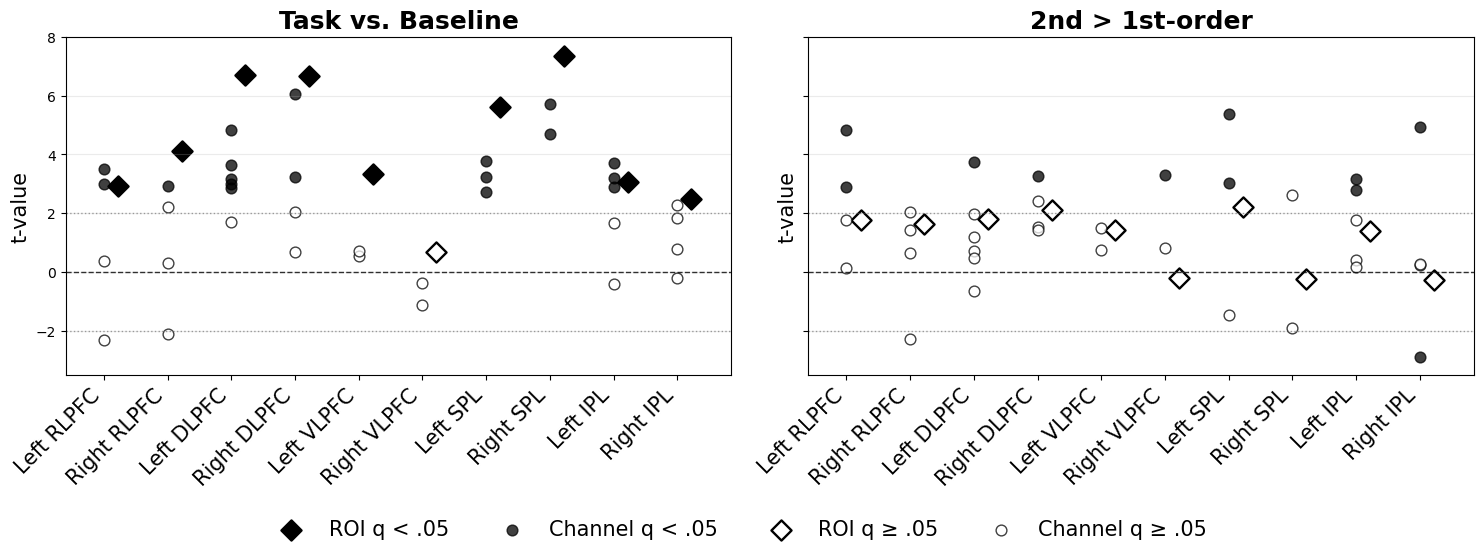

In [33]:
# ============================================================
# Figure: Channel- and ROI-level activation summary
# Two-panel grouped dot plot:
#   A. Task vs. Baseline
#   B. 2nd > 1st-order
#
# Edited version:
#   - Channel dots are NOT jittered
#   - ROI diamonds ARE jittered slightly to the right
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------
# Manual data entry
# ----------------------------

rows = [
    # ROI, Channel, Task channel t, Task channel q, Task ROI t, Task ROI q,
    # Contrast channel t, Contrast channel q, Contrast ROI t, Contrast ROI q

    ["Left RLPFC", "S1_D1", 0.39, 0.794, 2.93, 0.006, 2.88, 0.030, 1.79, 0.190],
    ["Left RLPFC", "S1_D2", -2.29, 0.050, 2.93, 0.006, 0.15, 0.900, 1.79, 0.190],
    ["Left RLPFC", "S2_D1", 2.99, 0.016, 2.93, 0.006, 1.76, 0.210, 1.79, 0.190],
    ["Left RLPFC", "S2_D2", 3.49, 0.005, 2.93, 0.006, 4.82, 0.000, 1.79, 0.190],

    ["Right RLPFC", "S6_D5", -2.09, 0.080, 4.11, 0.000, -2.27, 0.100, 1.65, 0.200],
    ["Right RLPFC", "S6_D6", 0.31, 0.827, 4.11, 0.000, 1.44, 0.320, 1.65, 0.200],
    ["Right RLPFC", "S7_D5", 2.22, 0.060, 4.11, 0.000, 0.65, 0.650, 1.65, 0.200],
    ["Right RLPFC", "S7_D6", 2.92, 0.013, 4.11, 0.000, 2.06, 0.130, 1.65, 0.200],

    ["Left DLPFC", "S4_D3", 3.63, 0.003, 6.70, 0.000, 1.99, 0.150, 1.80, 0.190],
    ["Left DLPFC", "S4_D2", 1.69, 0.160, 6.70, 0.000, 3.76, 0.003, 1.80, 0.190],
    ["Left DLPFC", "S4_D4", 2.85, 0.014, 6.70, 0.000, 1.19, 0.450, 1.80, 0.190],
    ["Left DLPFC", "S5_D3", 3.15, 0.008, 6.70, 0.000, -0.65, 0.650, 1.80, 0.190],
    ["Left DLPFC", "S5_D4", 4.83, 0.000, 6.70, 0.000, 0.73, 0.620, 1.80, 0.190],
    ["Left DLPFC", "S2_D3", 2.99, 0.011, 6.70, 0.000, 0.49, 0.720, 1.80, 0.190],

    ["Right DLPFC", "S7_D7", 3.23, 0.007, 6.66, 0.000, 2.41, 0.080, 2.13, 0.200],
    ["Right DLPFC", "S8_D5", 0.68, 0.670, 6.66, 0.000, 1.52, 0.320, 2.13, 0.200],
    ["Right DLPFC", "S8_D7", 6.05, 0.000, 6.66, 0.000, 3.27, 0.010, 2.13, 0.200],
    ["Right DLPFC", "S10_D7", 2.04, 0.080, 6.66, 0.000, 1.43, 0.320, 2.13, 0.200],

    ["Left VLPFC", "S3_D1", 0.55, 0.720, 3.33, 0.002, 1.49, 0.320, 1.45, 0.235],
    ["Left VLPFC", "S3_D3", 0.73, 0.650, 3.33, 0.002, 0.75, 0.620, 1.45, 0.235],

    ["Right VLPFC", "S9_D7", -0.35, 0.810, 0.67, 0.503, 0.82, 0.590, -0.18, 0.854],
    ["Right VLPFC", "S9_D6", -1.12, 0.420, 0.67, 0.503, 3.29, 0.010, -0.18, 0.854],

    ["Left SPL", "S12_D8", 3.23, 0.007, 5.60, 0.000, -1.46, 0.320, 2.21, 0.176],
    ["Left SPL", "S12_D10", 2.73, 0.018, 5.60, 0.000, 5.37, 0.000, 2.21, 0.176],
    ["Left SPL", "S13_D10", 3.77, 0.002, 5.60, 0.000, 3.02, 0.020, 2.21, 0.176],

    ["Right SPL", "S14_D12", 4.71, 0.000, 7.34, 0.001, -1.90, 0.180, -0.245, 0.853],
    ["Right SPL", "S16_D13", 5.70, 0.000, 7.34, 0.001, 2.62, 0.050, -0.245, 0.853],

    ["Left IPL", "S11_D9", -0.40, 0.810, 3.08, 0.004, 0.41, 0.770, 1.40, 0.235],
    ["Left IPL", "S11_D8", 3.20, 0.007, 3.08, 0.004, 3.15, 0.020, 1.40, 0.235],
    ["Left IPL", "S13_D8", 2.90, 0.013, 3.08, 0.004, 0.19, 0.890, 1.40, 0.235],
    ["Left IPL", "S13_D9", 1.67, 0.160, 3.08, 0.004, 2.79, 0.030, 1.40, 0.235],
    ["Left IPL", "S13_D11", 3.72, 0.002, 3.08, 0.004, 1.77, 0.210, 1.40, 0.235],

    ["Right IPL", "S15_D12", 1.85, 0.120, 2.50, 0.016, 0.24, 0.870, -0.28, 0.854],
    ["Right IPL", "S15_D14", -0.18, 0.896, 2.50, 0.016, -2.88, 0.030, -0.28, 0.854],
    ["Right IPL", "S16_D14", 0.80, 0.602, 2.50, 0.016, 4.92, 0.000, -0.28, 0.854],
    ["Right IPL", "S16_D15", 2.30, 0.050, 2.50, 0.016, 0.27, 0.850, -0.28, 0.854],
]

df = pd.DataFrame(
    rows,
    columns=[
        "ROI", "Channel",
        "Task_Channel_t", "Task_Channel_q",
        "Task_ROI_t", "Task_ROI_q",
        "Contrast_Channel_t", "Contrast_Channel_q",
        "Contrast_ROI_t", "Contrast_ROI_q"
    ]
)

# ----------------------------
# Plot settings
# ----------------------------

roi_order = [
    "Left RLPFC", "Right RLPFC",
    "Left DLPFC", "Right DLPFC",
    "Left VLPFC", "Right VLPFC",
    "Left SPL", "Right SPL",
    "Left IPL", "Right IPL"
]

roi_x = {roi: i for i, roi in enumerate(roi_order)}
df["x"] = df["ROI"].map(roi_x)

# Channel dots are intentionally NOT jittered
df["channel_x"] = df["x"]

# ROI-level data: one row per ROI
roi_df = (
    df.groupby("ROI", as_index=False)
      .agg(
          Task_ROI_t=("Task_ROI_t", "first"),
          Task_ROI_q=("Task_ROI_q", "first"),
          Contrast_ROI_t=("Contrast_ROI_t", "first"),
          Contrast_ROI_q=("Contrast_ROI_q", "first")
      )
)

roi_df["x"] = roi_df["ROI"].map(roi_x)

# ROI diamonds ARE jittered slightly to the right
# Increase or decrease this value if you want the diamonds farther from/closer to the channel dots.
roi_diamond_jitter = 0.22
roi_df["diamond_x"] = roi_df["x"] + roi_diamond_jitter

# ----------------------------
# Helper function
# ----------------------------

def plot_panel(
    ax,
    channel_t_col,
    channel_q_col,
    roi_t_col,
    roi_q_col,
    title
):
    # Significant ROI diamonds
    roi_sig = roi_df[roi_df[roi_q_col] < 0.05]
    ax.scatter(
        roi_sig["diamond_x"],
        roi_sig[roi_t_col],
        s=105,
        marker="D",
        facecolors="black",
        edgecolors="black",
        linewidths=1.7,
        label="ROI q < .05"
    )
    # Significant channel values
    sig = df[df[channel_q_col] < 0.05]
    ax.scatter(
        sig["channel_x"],
        sig[channel_t_col],
        s=60,
        facecolors="black",
        edgecolors="black",
        linewidths=1,
        alpha=0.75,
        label="Channel q < .05"
    )

    # Nonsignificant ROI diamonds
    roi_nonsig = roi_df[roi_df[roi_q_col] >= 0.05]
    ax.scatter(
        roi_nonsig["diamond_x"],
        roi_nonsig[roi_t_col],
        s=105,
        marker="D",
        facecolors="white",
        edgecolors="black",
        linewidths=1.7,
        label="ROI q ≥ .05"
    )
    
    # Nonsignificant channel values
    nonsig = df[df[channel_q_col] >= 0.05]
    ax.scatter(
        nonsig["channel_x"],
        nonsig[channel_t_col],
        s=60,
        facecolors="white",
        edgecolors="black",
        linewidths=1,
        alpha=0.75,
        label="Channel q ≥ .05"
    )
    

    # Reference lines
    ax.axhline(0, linestyle="--", linewidth=1, color="black", alpha=0.8)
    ax.axhline(2, linestyle=":", linewidth=1, color="black", alpha=0.35)
    ax.axhline(-2, linestyle=":", linewidth=1, color="black", alpha=0.35)

    # Formatting
    ax.set_title(title, fontsize=18, fontweight="bold")
    ax.set_ylabel("t-value", fontsize=15)
    ax.set_xticks(range(len(roi_order)))
    ax.set_xticklabels(roi_order, rotation=45, ha="right", fontsize=15)
    ax.set_xlim(-0.6, len(roi_order) - 0.15)
    ax.set_ylim(-3.5, 8.0)
    ax.grid(axis="y", alpha=0.25)

# ----------------------------
# Create figure
# ----------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

plot_panel(
    axes[0],
    channel_t_col="Task_Channel_t",
    channel_q_col="Task_Channel_q",
    roi_t_col="Task_ROI_t",
    roi_q_col="Task_ROI_q",
    title="Task vs. Baseline"
)

plot_panel(
    axes[1],
    channel_t_col="Contrast_Channel_t",
    channel_q_col="Contrast_Channel_q",
    roi_t_col="Contrast_ROI_t",
    roi_q_col="Contrast_ROI_q",
    title="2nd > 1st-order"
)

# Make one shared legend BELOW the plots
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.06),
    ncol=4,
    frameon=False,
    fontsize=15
)

# fig.text(
#     0.5,
#     0.01,
#     "Summary of Channel- and ROI-Level Activation Effects",
#     ha="center",
#     va="bottom",
#     fontsize=15,
#     fontweight="bold"
# )

# Leave room at the bottom for legend and title
fig.tight_layout(rect=[0, 0.15, 1, 1])

# ----------------------------
# Save high-resolution files
# ----------------------------

plt.savefig(
    r"C:\Users\pkell\Downloads\activation_summary_dotplot.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    r"C:\Users\pkell\Downloads\activation_summary_dotplot.pdf",
    bbox_inches="tight"
)

plt.show()

In [3]:
## GROUP LEVEL DATA - contrast 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Enable interactive plotting (optional)
%matplotlib qt

# Load combined CSV file
file = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\combined_contrast_power_analysis_results.csv"
df = pd.read_csv(file)

# Optional: Filter to HbO only (if applicable)
if 'type' in df.columns:
    df = df[df['type'].str.lower() == 'hbo']

# --- Drop Rows with Detector in {16–23} ---
bad_detectors = {16, 17, 18, 19, 20, 21, 22, 23}
df = df[~df['detector'].isin(bad_detectors)]

# --- Drop Specific Source-Detector Pairs ---
df = df[~((df['source'] == 14) & (df['detector'] == 13))]
df = df[~((df['source'] == 16) & (df['detector'] == 12))]

# --- Compute summary statistics per block count ---
summary_df = df.groupby('n_blocks').agg(
    mean_tstat=('tstat', 'mean'),
    median_tstat=('tstat', 'median'),
    prop_sig_p=('q', lambda x: (x < 0.05).mean()),
    var_tstat=('tstat', 'var'),
    std_tstat=('tstat', 'std'),
    n_channels=('tstat', 'count'),
    mean_beta=('beta', 'mean'),
    mean_se=('se', 'mean'),
    beta_sem=('beta', lambda x: stats.sem(x, nan_policy='omit')),
    se_sem=('se', lambda x: stats.sem(x, nan_policy='omit'))
).reset_index()

# --- Compute 95% confidence intervals ---
t_critical = stats.t.ppf(0.975, df=summary_df['n_channels'] - 1)

summary_df['beta_ci95'] = summary_df['beta_sem'] * t_critical
summary_df['se_ci95'] = summary_df['se_sem'] * t_critical

summary_df['beta_ci_lower'] = summary_df['mean_beta'] - summary_df['beta_ci95']
summary_df['beta_ci_upper'] = summary_df['mean_beta'] + summary_df['beta_ci95']

summary_df['se_ci_lower'] = summary_df['mean_se'] - summary_df['se_ci95']
summary_df['se_ci_upper'] = summary_df['mean_se'] + summary_df['se_ci95']

# Optional: rename for clarity
contrast_summary = summary_df

# --- Print final summary with CI bounds ---
print(contrast_summary)


   n_blocks  mean_tstat  median_tstat  prop_sig_p  var_tstat  std_tstat  \
0         3    0.442757      1.215122    0.694444  10.226760   3.197931   
1         6    2.820282      3.298777    0.666667  14.704445   3.834638   
2         9    1.637994      1.955532    0.638889  19.638622   4.431548   
3        12    0.795022      1.244985    0.388889   8.247318   2.871814   
4        15    0.180980      0.731269    0.583333  10.604754   3.256494   
5        18    0.841678      1.031915    0.333333   7.734887   2.781166   

   n_channels  mean_beta   mean_se  beta_sem    se_sem  beta_ci95   se_ci95  \
0          36   0.187126  0.761480  0.415394  0.027839   0.843295  0.056515   
1          36   1.437988  0.499053  0.304255  0.019279   0.617670  0.039139   
2          36   0.536472  0.371441  0.302128  0.015756   0.613352  0.031987   
3          36   0.286810  0.346515  0.182034  0.014225   0.369548  0.028877   
4          36   0.057187  0.318763  0.187191  0.013336   0.380019  0.027074   


In [5]:
## Beta and SE plot 

import matplotlib.pyplot as plt

# Prefix the columns to indicate their source
contrast_labeled = contrast_summary.add_prefix('contrast_')
tvr_labeled = tvr_summary.add_prefix('tvr_')

# Combine side by side (column-wise)
combined_df = pd.concat([contrast_labeled, tvr_labeled], axis=1)

# Display the result
print(combined_df.head())

# --- Line plots comparing each contrast separately ---
fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharex=True)
x_ticks = combined_df['tvr_n_blocks'].unique()
plt.rcParams.update({'font.size': 16})

# === Plot for Task vs. Baseline ===
ax1 = axes[0]
ax1.plot(combined_df['tvr_n_blocks'], combined_df['tvr_mean_beta'], 'o-', color='red', label='Mean Beta')
ax1.fill_between(combined_df['tvr_n_blocks'],
                 combined_df['tvr_beta_ci_lower'], combined_df['tvr_beta_ci_upper'],
                 color='red', alpha=0.3, label='Beta 95% CI')
ax1.set_xlabel('Cumulative Number of Blocks', fontsize=16)
ax1.set_ylabel('Mean Beta', fontsize=16, color='red')
ax1.tick_params(axis='y', labelcolor='red')
ax1.set_title('Task vs. Baseline', fontsize=18)
ax1.set_xticks(x_ticks)
ax1.set_ylim(0.0, 3.0)
ax1.grid(True, linestyle='--', alpha=0.5)

ax1b = ax1.twinx()
ax1b.plot(combined_df['tvr_n_blocks'], combined_df['tvr_mean_se'], 's-', color='blue', label='SE')
ax1b.fill_between(combined_df['tvr_n_blocks'],
                  combined_df['tvr_se_ci_lower'], combined_df['tvr_se_ci_upper'],
                  color='blue', alpha=0.3, label='SE 95% CI')
ax1b.set_ylabel('SE', fontsize=16, color='blue')
ax1b.tick_params(axis='y', labelcolor='blue')
ax1b.set_ylim(0.0, 1.0)
ax1b.grid(True, linestyle='--', alpha=0.5)

# === Plot for 2nd vs. 1st ===
ax2 = axes[1]
ax2.plot(combined_df['contrast_n_blocks'], combined_df['contrast_mean_beta'], 'o-', color='red', label='Mean Beta')
ax2.fill_between(combined_df['contrast_n_blocks'],
                 combined_df['contrast_beta_ci_lower'], combined_df['contrast_beta_ci_upper'],
                 color='red', alpha=0.3, label='Beta 95% CI')
ax2.set_xlabel('Cumulative Number of Blocks', fontsize=16)
ax2.set_ylabel('Mean Beta', fontsize=16, color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_title('2nd vs. 1st Order', fontsize=18)
ax2.set_xticks(x_ticks)
ax2.set_ylim(0.0, 3.0)
ax2.grid(True, linestyle='--', alpha=0.5)

ax2b = ax2.twinx()
ax2b.plot(combined_df['contrast_n_blocks'], combined_df['contrast_mean_se'], 's-', color='blue', label='SE')
ax2b.fill_between(combined_df['contrast_n_blocks'],
                  combined_df['contrast_se_ci_lower'], combined_df['contrast_se_ci_upper'],
                  color='blue', alpha=0.3, label='SE 95% CI')
ax2b.set_ylabel('SE', fontsize=16, color='blue')
ax2b.tick_params(axis='y', labelcolor='blue')
ax2b.set_ylim(0.0, 1.0)
ax2b.grid(True, linestyle='--', alpha=0.5)

# --- Combine all legend handles and place one shared legend outside the figure ---
handles = (
    ax1.get_legend_handles_labels()[0] +
    ax1b.get_legend_handles_labels()[0]
)
labels = (
    ax1.get_legend_handles_labels()[1] +
    ax1b.get_legend_handles_labels()[1]
)

fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=14, title='Metric')
plt.tight_layout(rect=[0, 0, 0.92, 1])  # Leave space for legend

# --- Save figure ---
save_path = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Figures\beta_se_plot.png"  # <-- EDIT THIS PATH
plt.savefig(save_path, dpi=300)
print(f"📁 Figure saved as: {save_path}")
    
plt.show()


   contrast_n_blocks  contrast_mean_tstat  contrast_median_tstat  \
0                  3             0.442757               1.215122   
1                  6             2.820282               3.298777   
2                  9             1.637994               1.955532   
3                 12             0.795022               1.244985   
4                 15             0.180980               0.731269   

   contrast_prop_sig_p  contrast_var_tstat  contrast_std_tstat  \
0             0.694444           10.226760            3.197931   
1             0.666667           14.704445            3.834638   
2             0.638889           19.638622            4.431548   
3             0.388889            8.247318            2.871814   
4             0.583333           10.604754            3.256494   

   contrast_n_channels  contrast_mean_beta  contrast_mean_se  \
0                   36            0.187126          0.761480   
1                   36            1.437988          0.499053   
2 

In [22]:
# Prefix the columns to indicate their source
contrast_labeled = contrast_summary.add_prefix('contrast_')
tvr_labeled = tvr_summary.add_prefix('tvr_')

# Combine side by side (column-wise)
combined_df = pd.concat([contrast_labeled, tvr_labeled], axis=1)

# Display the result
print(combined_df.head())

import matplotlib.pyplot as plt

# --- Line plots comparing contrast and TVR metrics across blocks ---

fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharex=True)

# Use either column for consistent x-axis ticks
x_ticks = combined_df['tvr_n_blocks'].unique()

# --- Set global font size ---
plt.rcParams.update({'font.size': 16})

# # Plot Mean T-Values
# axes[0].plot(combined_df['contrast_n_blocks'], combined_df['contrast_mean_tstat'], marker='o', label='2nd vs. 1st')
# axes[0].plot(combined_df['tvr_n_blocks'], combined_df['tvr_mean_tstat'], marker='o', label='Task vs. Baseline')
# axes[0].set_title('Mean T-Value Across Block Counts', fontsize=18)
# axes[0].set_xlabel('Cumulative Number of Blocks', fontsize=16)
# axes[0].set_ylabel('Mean T-Value', fontsize=16)
# axes[0].tick_params(axis='both', labelsize=14)
# axes[0].legend(fontsize=14)
# axes[0].set_xticks(x_ticks)

# Plot Number of Significant Channels
axes[0].plot(combined_df['contrast_n_blocks'], combined_df['contrast_prop_sig_p'], marker='o', label='2nd vs. 1st')
axes[0].plot(combined_df['tvr_n_blocks'], combined_df['tvr_prop_sig_p'], marker='o', label='Task vs. Baseline')
axes[0].set_title('Significant Channels Across Block Counts')
axes[0].set_xlabel('Number of Blocks')
axes[0].set_ylabel('Significant Channels')
axes[0].legend()
axes[0].set_xticks(x_ticks)

# # Plot Variance of T-Values
# axes[2].plot(combined_df['contrast_n_blocks'], combined_df['contrast_var_tstat'], marker='o', label='2nd vs. 1st')
# axes[2].plot(combined_df['tvr_n_blocks'], combined_df['tvr_var_tstat'], marker='o', label='Task vs. Baseline')
# axes[2].set_title('Variance of T-Values Across Block Counts', fontsize=18)
# axes[2].set_xlabel('Cumulative Number of Blocks', fontsize=16)
# axes[2].set_ylabel('Variance', fontsize=16)
# axes[2].tick_params(axis='both', labelsize=14)
# axes[2].legend(fontsize=14)
# axes[2].set_xticks(x_ticks)

plt.tight_layout()
plt.show()


   contrast_n_blocks  contrast_mean_tstat  contrast_median_tstat  \
0                  3             0.442757               1.215122   
1                  6             2.820282               3.298777   
2                  9             1.637994               1.955532   
3                 12             0.795022               1.244985   
4                 15             0.180980               0.731269   

   contrast_prop_sig_p  contrast_var_tstat  contrast_std_tstat  \
0             0.694444           10.226760            3.197931   
1             0.666667           14.704445            3.834638   
2             0.638889           19.638622            4.431548   
3             0.388889            8.247318            2.871814   
4             0.583333           10.604754            3.256494   

   contrast_n_channels  contrast_mean_beta  contrast_mean_se  \
0                   36            0.187126          0.761480   
1                   36            1.437988          0.499053   
2 

In [227]:
import matplotlib.pyplot as plt

# Prefix the columns to indicate their source
contrast_labeled = contrast_summary.add_prefix('contrast_')
tvr_labeled = tvr_summary.add_prefix('tvr_')

# Combine side by side (column-wise)
combined_df = pd.concat([contrast_labeled, tvr_labeled], axis=1)

# Display the result
print(combined_df.head())

# --- Add placeholder standard error columns if not already present ---
if 'tvr_beta_se' not in combined_df.columns:
    combined_df['tvr_beta_se'] = 0  # Replace 0 with actual SE if available
if 'contrast_beta_se' not in combined_df.columns:
    combined_df['contrast_beta_se'] = 0
if 'tvr_se_se' not in combined_df.columns:
    combined_df['tvr_se_se'] = 0
if 'contrast_se_se' not in combined_df.columns:
    combined_df['contrast_se_se'] = 0

# --- Line plots comparing each contrast separately ---
fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharex=True)

x_ticks = combined_df['tvr_n_blocks'].unique()
plt.rcParams.update({'font.size': 16})

# === Plot for Task vs. Baseline ===
ax1 = axes[0]
ax1.errorbar(combined_df['tvr_n_blocks'], combined_df['tvr_mean_beta'],
             yerr=combined_df['tvr_beta_se'], fmt='o-', color='red', label='Mean Beta', capsize=5)
ax1.set_xlabel('Cumulative Number of Blocks', fontsize=16)
ax1.set_ylabel('Mean Beta', fontsize=16, color='red')
ax1.tick_params(axis='y', labelcolor='red')
ax1.set_title('Task vs. Baseline', fontsize=18)
ax1.set_xticks(x_ticks)
ax1.set_ylim(0.0, 3.0)

ax1b = ax1.twinx()
ax1b.errorbar(combined_df['tvr_n_blocks'], combined_df['tvr_mean_se'],
              yerr=combined_df['tvr_se_se'], fmt='s-', color='blue', label='SE', capsize=5)
ax1b.set_ylabel('SE', fontsize=16, color='blue')
ax1b.tick_params(axis='y', labelcolor='blue')
ax1b.set_ylim(0.0, 1.0)

# === Plot for 2nd vs. 1st ===
ax2 = axes[1]
ax2.errorbar(combined_df['contrast_n_blocks'], combined_df['contrast_mean_beta'],
             yerr=combined_df['contrast_beta_se'], fmt='o-', color='red', label='Mean Beta', capsize=5)
ax2.set_xlabel('Cumulative Number of Blocks', fontsize=16)
ax2.set_ylabel('Mean Beta', fontsize=16, color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_title('2nd vs. 1st Order', fontsize=18)
ax2.set_xticks(x_ticks)
ax2.set_ylim(0.0, 3.0)

ax2b = ax2.twinx()
ax2b.errorbar(combined_df['contrast_n_blocks'], combined_df['contrast_mean_se'],
              yerr=combined_df['contrast_se_se'], fmt='s-', color='blue', label='SE', capsize=5)
ax2b.set_ylabel('SE', fontsize=16, color='blue')
ax2b.tick_params(axis='y', labelcolor='blue')
ax2b.set_ylim(0.0, 1.0)

# --- Combine all legend handles and place one shared legend outside the figure ---
handles = (
    ax1.get_legend_handles_labels()[0] +
    ax1b.get_legend_handles_labels()[0]
)
labels = (
    ax1.get_legend_handles_labels()[1] +
    ax1b.get_legend_handles_labels()[1]
)

fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=14, title='Metric')

plt.tight_layout(rect=[0, 0, 0.92, 1])  # Leave space for legend
plt.show()


   contrast_n_blocks  contrast_mean_tstat  contrast_median_tstat  \
0                  3             0.419670               0.884035   
1                  6             2.904431               3.081793   
2                  9             0.901098               0.484575   
3                 12             0.400589               0.806527   
4                 15             0.239225               0.867823   

   contrast_prop_sig_p  contrast_var_tstat  contrast_std_tstat  \
0             0.608696            8.858058            2.976249   
1             0.695652           17.468736            4.179562   
2             0.630435           18.685916            4.322721   
3             0.369565            8.687582            2.947470   
4             0.565217           10.507598            3.241543   

   contrast_n_channels  contrast_mean_beta  contrast_mean_se  \
0                   46            0.225924          0.820640   
1                   46            1.597365          0.540005   
2 

In [225]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# Load your data
data_tvr = pd.read_csv(r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\power_analysis_combined.csv")
data_2v1 = pd.read_csv(r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\combined_contrast_power_analysis_results.csv")

# Create channel column in format S#D#
for df in [data_tvr, data_2v1]:
    df['channel'] = 'S' + df['source'].astype(str) + 'D' + df['detector'].astype(str)

# Define ROI mappings
roi_definitions = {
    "Left RLPFC": ['S1D1', 'S1D2', 'S2D1', 'S2D2'],
    "Left DLPFC": ['S4D3', 'S4D2', 'S4D4', 'S5D3', 'S5D4', 'S5D16', 'S2D3'],
    "Left VLPFC": ['S3D1', 'S3D3'],
    "Left Sup Parietal": ['S12D8', 'S12D10', 'S13D10', 'S13D20', 'S12D19'],
    "Left Inf Parietal": ['S11D9', 'S11D8', 'S13D8', 'S13D9', 'S13D11', 'S11D18'],
    "Right RLPFC": ['S6D5', 'S6D6', 'S7D5', 'S7D6'],
    "Right DLPFC": ['S7D7', 'S8D5', 'S8D7', 'S10D7', 'S10D17'],
    "Right VLPFC": ['S9D7', 'S9D6'],
    "Right Sup Parietal": ['S14D12', 'S14D13', 'S14D21', 'S16D13'],
    "Right Inf Parietal": ['S15D12', 'S15D14', 'S16D12', 'S16D14', 'S16D15', 'S15D22', 'S16D23']
}
roi_map = {ch: roi for roi, chans in roi_definitions.items() for ch in chans}

# Significance colors
alpha_threshold = 0.05
category_colors = {
    "Significant Negative": "#4575B4",
    "Non-Significant": "#CCCCCC",
    "Significant Positive": "#D73027"
}
roi_palette = sns.color_palette("tab10", n_colors=len(roi_definitions))
roi_colors = {roi: roi_palette[i] for i, roi in enumerate(roi_definitions)}

# Assign significance
def assign_significance(df):
    df = df.copy()
    df['significance_category'] = "Non-Significant"
    df.loc[(df['p'] < alpha_threshold) & (df['tstat'] > 0), 'significance_category'] = "Significant Positive"
    df.loc[(df['p'] < alpha_threshold) & (df['tstat'] < 0), 'significance_category'] = "Significant Negative"
    df['significance_category'] = pd.Categorical(
        df['significance_category'],
        categories=["Significant Negative", "Non-Significant", "Significant Positive"],
        ordered=True
    )
    return df

# Channel sort helper
def sort_channels_by_s(channels):
    return sorted(channels, key=lambda x: int(x.split('D')[0].replace('S', '')))

# Plot function
def plot_channel_progression(df, title):
    df = assign_significance(df)
    df = df[df['channel'].isin(roi_map)]
    df['roi'] = df['channel'].map(roi_map)

    channel_order = sort_channels_by_s(df['channel'].unique())
    df['channel_order'] = pd.Categorical(df['channel'], categories=channel_order, ordered=True)

    fig, ax = plt.subplots(figsize=(14, 12))

    for channel in channel_order:
        channel_df = df[df['channel'] == channel].sort_values('n_blocks')
        blocks = channel_df['n_blocks'].values
        sigs = channel_df['significance_category'].values
        for i in range(len(blocks) - 1):
            x_vals = [blocks[i], blocks[i + 1]]
            y_vals = [channel, channel]
            sig_color = category_colors.get(sigs[i], "#000000")
            ax.plot(x_vals, y_vals, color=sig_color, linewidth=3, alpha=0.9)

    ax.set_title(title, fontsize=18, weight='bold')
    ax.set_xlabel("Number of Blocks", fontsize=14)
    ax.set_ylabel("Channel", fontsize=14)
    ax.set_xticks(sorted(df['n_blocks'].unique()))
    ax.set_yticks(range(len(channel_order)))
    ax.set_yticklabels(channel_order, fontsize=7)
    ax.invert_yaxis()
    ax.grid(True, axis='x', linestyle='--', alpha=0.5)

    # Color y-axis tick labels by ROI
    for tick_label in ax.get_yticklabels():
        channel = tick_label.get_text()
        roi = roi_map.get(channel, "")
        tick_label.set_color(roi_colors.get(roi, "black"))

    # Legends
    legend_lines_sig = [Line2D([0], [0], color=color, lw=4) for color in category_colors.values()]
    legend_labels_sig = list(category_colors.keys())
    sig_legend = ax.legend(legend_lines_sig, legend_labels_sig, title="Significance", loc='lower left', fontsize=10)
    ax.add_artist(sig_legend)

    legend_lines_roi = [Line2D([0], [0], color=roi_colors[roi], lw=4) for roi in roi_definitions]
    legend_labels_roi = list(roi_definitions.keys())
    fig.legend(legend_lines_roi, legend_labels_roi, loc='lower center', title="ROI", ncol=3, fontsize=9)

    plt.tight_layout()
    plt.show()

# Plot results
plot_channel_progression(data_tvr, "Channel Significance Progression Across Blocks (Task vs. Rest)")
plot_channel_progression(data_2v1, "Channel Significance Progression Across Blocks (2nd vs. 1st)")


In [7]:
## Behavioral Power Analysis x3 

import os
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# --- Setup ---
data_dir = r'C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\behavioral data\data'

# --- Initialize master dataframe ---
all_data = []

# --- Load and combine data ---
for file in os.listdir(data_dir):
    if file.endswith('.csv'):
        df = pd.read_csv(os.path.join(data_dir, file))
        df['participant'] = os.path.splitext(file)[0]
        all_data.append(df)

full_data = pd.concat(all_data, ignore_index=True)

# --- Convert relevant columns to numeric safely ---
full_data['thisRow.t'] = pd.to_numeric(full_data['thisRow.t'], errors='coerce')

# --- Define condition labels ---
labels = {1: '1st Order', 2: '2nd Order'}

# --- Mapping of block count to row count ---
row_cutoffs = {
    3: 56,
    6: 77,
    9: 100,
    12: 121,
    15: 142,
    18: 162
}

# --- Store summaries for each step ---
all_summaries = []

# --- Loop through each row cutoff ---
for block_count, row_limit in row_cutoffs.items():
    subset = full_data.iloc[:row_limit].copy()

    if subset.empty or 'cond' not in subset.columns:
        print(f"⚠️ No valid data for block count {block_count}. Skipping.")
        continue

    summary = subset.groupby('cond').agg(
        accuracy_mean=('key_resp_2.corr', 'mean'),
        rt_mean=('key_resp_2.rt', 'mean'),
        accuracy_count=('key_resp_2.corr', 'count'),
        rt_count=('key_resp_2.rt', 'count'),
        accuracy_sem=('key_resp_2.corr', lambda x: stats.sem(x, nan_policy='omit')),
        rt_sem=('key_resp_2.rt', lambda x: stats.sem(x, nan_policy='omit'))
    ).reset_index()

    summary['block_count'] = block_count
    summary['accuracy_ci95'] = summary['accuracy_sem'] * stats.t.ppf(0.975, summary['accuracy_count'] - 1)
    summary['rt_ci95'] = summary['rt_sem'] * stats.t.ppf(0.975, summary['rt_count'] - 1)

    all_summaries.append(summary)

# --- Combine all summaries ---
summary_df = pd.concat(all_summaries, ignore_index=True)

import matplotlib.pyplot as plt

# --- Plotting ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Define x-ticks for block counts
block_counts = [3, 6, 9, 12, 15, 18]

# Accuracy plot
for cond in summary_df['cond'].unique():
    data = summary_df[summary_df['cond'] == cond]
    axes[0].errorbar(data['block_count'], data['accuracy_mean'], yerr=data['accuracy_ci95'],
                     label=labels.get(cond, str(cond)), marker='o', capsize=4)
# axes[0].set_title('Accuracy by Condition Across Block Counts')
axes[0].set_xlabel('Cumulative Number of Blocks')
axes[0].set_ylabel('Mean Accuracy')
axes[0].set_xticks(block_counts)
axes[0].legend()
axes[0].set_facecolor('white')  # Ensure white background
axes[0].grid()             # grid lines - set as false to remove 

# Reaction Time plot
for cond in summary_df['cond'].unique():
    data = summary_df[summary_df['cond'] == cond]
    axes[1].errorbar(data['block_count'], data['rt_mean'], yerr=data['rt_ci95'],
                     label=labels.get(cond, str(cond)), marker='o', capsize=4)
# axes[1].set_title('Reaction Time by Condition Across Block Counts')
axes[1].set_xlabel('Cumulative Number of Blocks')
axes[1].set_ylabel('Mean Response Time (s)')
axes[1].set_xticks(block_counts)
axes[1].legend()
axes[1].set_facecolor('white')  # Ensure white background
axes[1].grid()             #  grid lines - set as false to remove

plt.tight_layout()

# # --- Save figure ---
# save_path = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Figures\nblocks_behavioralx3.png"  # <-- EDIT THIS PATH
# plt.savefig(save_path, dpi=300)
# print(f"📁 Figure saved as: {save_path}")
    
plt.show()


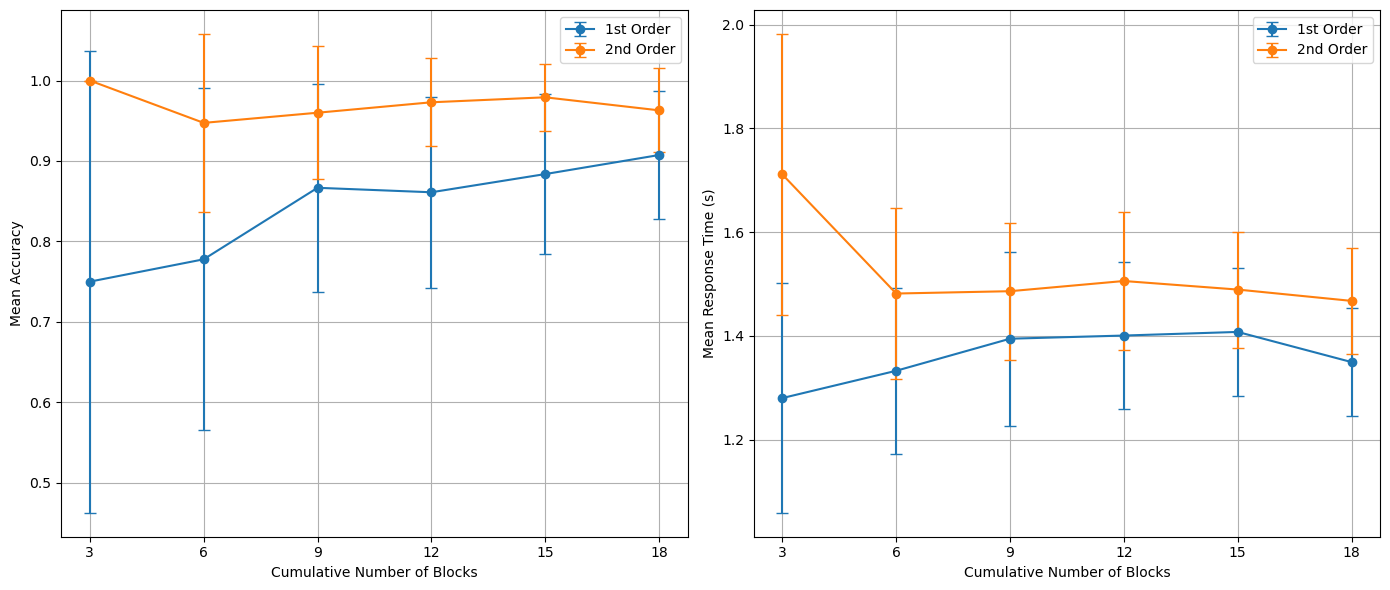

    cond  accuracy_mean   rt_mean  accuracy_count  rt_count  accuracy_sem  \
0    1.0       0.750000  1.280310              12        12      0.130558   
1    2.0       1.000000  1.711146               7         7      0.000000   
2    1.0       0.777778  1.332900              18        18      0.100832   
3    2.0       0.947368  1.481730              19        19      0.052632   
4    1.0       0.866667  1.394670              30        30      0.063124   
5    2.0       0.960000  1.486221              25        25      0.040000   
6    1.0       0.861111  1.400768              36        36      0.058456   
7    2.0       0.972973  1.505853              37        37      0.027027   
8    1.0       0.883721  1.407735              43        43      0.049463   
9    2.0       0.979167  1.489368              48        48      0.020833   
10   1.0       0.907407  1.349643              54        54      0.039815   
11   2.0       0.962963  1.467539              54        54      0.025941   

In [1]:
## Behavioral Power Analysis x3 

import os
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# --- Setup ---
data_dir = r'C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\behavioral data\data'

# --- Initialize master dataframe ---
all_data = []

# --- Load and combine data ---
for file in os.listdir(data_dir):
    if file.endswith('.csv'):
        df = pd.read_csv(os.path.join(data_dir, file))
        df['participant'] = os.path.splitext(file)[0]
        all_data.append(df)

full_data = pd.concat(all_data, ignore_index=True)

# --- Convert relevant columns to numeric safely ---
full_data['thisRow.t'] = pd.to_numeric(full_data['thisRow.t'], errors='coerce')

# --- Define condition labels ---
labels = {1: '1st Order', 2: '2nd Order'}

# --- Mapping of block count to row count ---
row_cutoffs = {
    3: 56,
    6: 77,
    9: 100,
    12: 121,
    15: 142,
    18: 162
}

# --- Helper function: 95% CI for SEM ---
def sem_ci_bounds(x, alpha=0.05):
    x = pd.Series(x).dropna()
    n = len(x)

    if n < 2:
        return pd.Series({
            'sem': np.nan,
            'sem_ci95_lower': np.nan,
            'sem_ci95_upper': np.nan,
            'sem_ci95_halfwidth': np.nan
        })

    s = np.std(x, ddof=1)
    sem = s / np.sqrt(n)

    chi2_lower = stats.chi2.ppf(alpha / 2, n - 1)
    chi2_upper = stats.chi2.ppf(1 - alpha / 2, n - 1)

    sd_ci_lower = np.sqrt((n - 1) * s**2 / chi2_upper)
    sd_ci_upper = np.sqrt((n - 1) * s**2 / chi2_lower)

    sem_ci_lower = sd_ci_lower / np.sqrt(n)
    sem_ci_upper = sd_ci_upper / np.sqrt(n)
    sem_ci_halfwidth = (sem_ci_upper - sem_ci_lower) / 2

    return pd.Series({
        'sem': sem,
        'sem_ci95_lower': sem_ci_lower,
        'sem_ci95_upper': sem_ci_upper,
        'sem_ci95_halfwidth': sem_ci_halfwidth
    })

# --- Store summaries for each step ---
all_summaries = []

# --- Loop through each row cutoff ---
for block_count, row_limit in row_cutoffs.items():
    subset = full_data.iloc[:row_limit].copy()

    if subset.empty or 'cond' not in subset.columns:
        print(f"⚠️ No valid data for block count {block_count}. Skipping.")
        continue

    summary = subset.groupby('cond').agg(
        accuracy_mean=('key_resp_2.corr', 'mean'),
        rt_mean=('key_resp_2.rt', 'mean'),
        accuracy_count=('key_resp_2.corr', 'count'),
        rt_count=('key_resp_2.rt', 'count'),
        accuracy_sem=('key_resp_2.corr', lambda x: stats.sem(x, nan_policy='omit')),
        rt_sem=('key_resp_2.rt', lambda x: stats.sem(x, nan_policy='omit'))
    ).reset_index()

    # --- ADD: calculate 95% CI bounds for SEM for accuracy and RT ---
    accuracy_sem_ci = subset.groupby('cond')['key_resp_2.corr'].apply(sem_ci_bounds).unstack().reset_index()
    accuracy_sem_ci = accuracy_sem_ci.rename(columns={
        'sem': 'accuracy_sem_check',
        'sem_ci95_lower': 'accuracy_sem_ci95_lower',
        'sem_ci95_upper': 'accuracy_sem_ci95_upper',
        'sem_ci95_halfwidth': 'accuracy_sem_ci95_halfwidth'
    })

    rt_sem_ci = subset.groupby('cond')['key_resp_2.rt'].apply(sem_ci_bounds).unstack().reset_index()
    rt_sem_ci = rt_sem_ci.rename(columns={
        'sem': 'rt_sem_check',
        'sem_ci95_lower': 'rt_sem_ci95_lower',
        'sem_ci95_upper': 'rt_sem_ci95_upper',
        'sem_ci95_halfwidth': 'rt_sem_ci95_halfwidth'
    })

    summary = summary.merge(accuracy_sem_ci, on='cond', how='left')
    summary = summary.merge(rt_sem_ci, on='cond', how='left')

    summary['block_count'] = block_count
    summary['accuracy_ci95'] = summary['accuracy_sem'] * stats.t.ppf(0.975, summary['accuracy_count'] - 1)
    summary['rt_ci95'] = summary['rt_sem'] * stats.t.ppf(0.975, summary['rt_count'] - 1)

    all_summaries.append(summary)

# --- Combine all summaries ---
summary_df = pd.concat(all_summaries, ignore_index=True)

import matplotlib.pyplot as plt

# --- Plotting ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Define x-ticks for block counts
block_counts = [3, 6, 9, 12, 15, 18]

# Accuracy plot
for cond in summary_df['cond'].unique():
    data = summary_df[summary_df['cond'] == cond]
    axes[0].errorbar(data['block_count'], data['accuracy_mean'], yerr=data['accuracy_ci95'],
                     label=labels.get(cond, str(cond)), marker='o', capsize=4)
# axes[0].set_title('Accuracy by Condition Across Block Counts')
axes[0].set_xlabel('Cumulative Number of Blocks')
axes[0].set_ylabel('Mean Accuracy')
axes[0].set_xticks(block_counts)
axes[0].legend()
axes[0].set_facecolor('white')  # Ensure white background
axes[0].grid()             # grid lines - set as false to remove 

# Reaction Time plot
for cond in summary_df['cond'].unique():
    data = summary_df[summary_df['cond'] == cond]
    axes[1].errorbar(data['block_count'], data['rt_mean'], yerr=data['rt_ci95'],
                     label=labels.get(cond, str(cond)), marker='o', capsize=4)
# axes[1].set_title('Reaction Time by Condition Across Block Counts')
axes[1].set_xlabel('Cumulative Number of Blocks')
axes[1].set_ylabel('Mean Response Time (s)')
axes[1].set_xticks(block_counts)
axes[1].legend()
axes[1].set_facecolor('white')  # Ensure white background
axes[1].grid()             #  grid lines - set as false to remove

plt.tight_layout()

# # --- Save figure ---
# save_path = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Figures\nblocks_behavioralx3.png"  # <-- EDIT THIS PATH
# plt.savefig(save_path, dpi=300)
# print(f"📁 Figure saved as: {save_path}")
    
plt.show()

# Optional: inspect the updated summary_df with new SEM CI columns
print(summary_df)

In [9]:
summary_df

,cond,accuracy_mean,rt_mean,accuracy_count,rt_count,accuracy_sem,rt_sem,block_count,accuracy_ci95,rt_ci95
0,1.0,0.750000,1.280310,12,12,0.130558,0.100425,3,0.287357,0.221034
1,2.0,1.000000,1.711146,7,7,0.000000,0.110648,3,0.000000,0.270747
2,1.0,0.777778,1.332900,18,18,0.100832,0.075927,6,0.212736,0.160192
3,2.0,0.947368,1.481730,19,19,0.052632,0.078252,6,0.110575,0.164400
4,1.0,0.866667,1.394670,30,30,0.063124,0.081954,9,0.129104,0.167616
5,2.0,0.960000,1.486221,25,25,0.040000,0.064059,9,0.082556,0.132210
6,1.0,0.861111,1.400768,36,36,0.058456,0.069989,12,0.118672,0.142085
7,2.0,0.972973,1.505853,37,37,0.027027,0.065924,12,0.054813,0.133700
8,1.0,0.883721,1.407735,43,43,0.049463,0.060787,15,0.099821,0.122672
9,2.0,0.979167,1.489368,48,48,0.020833,0.055585,15,0.041911,0.111822


📁 Figure saved as: C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Figures\behavior_accuracy_rt_se_plot.png


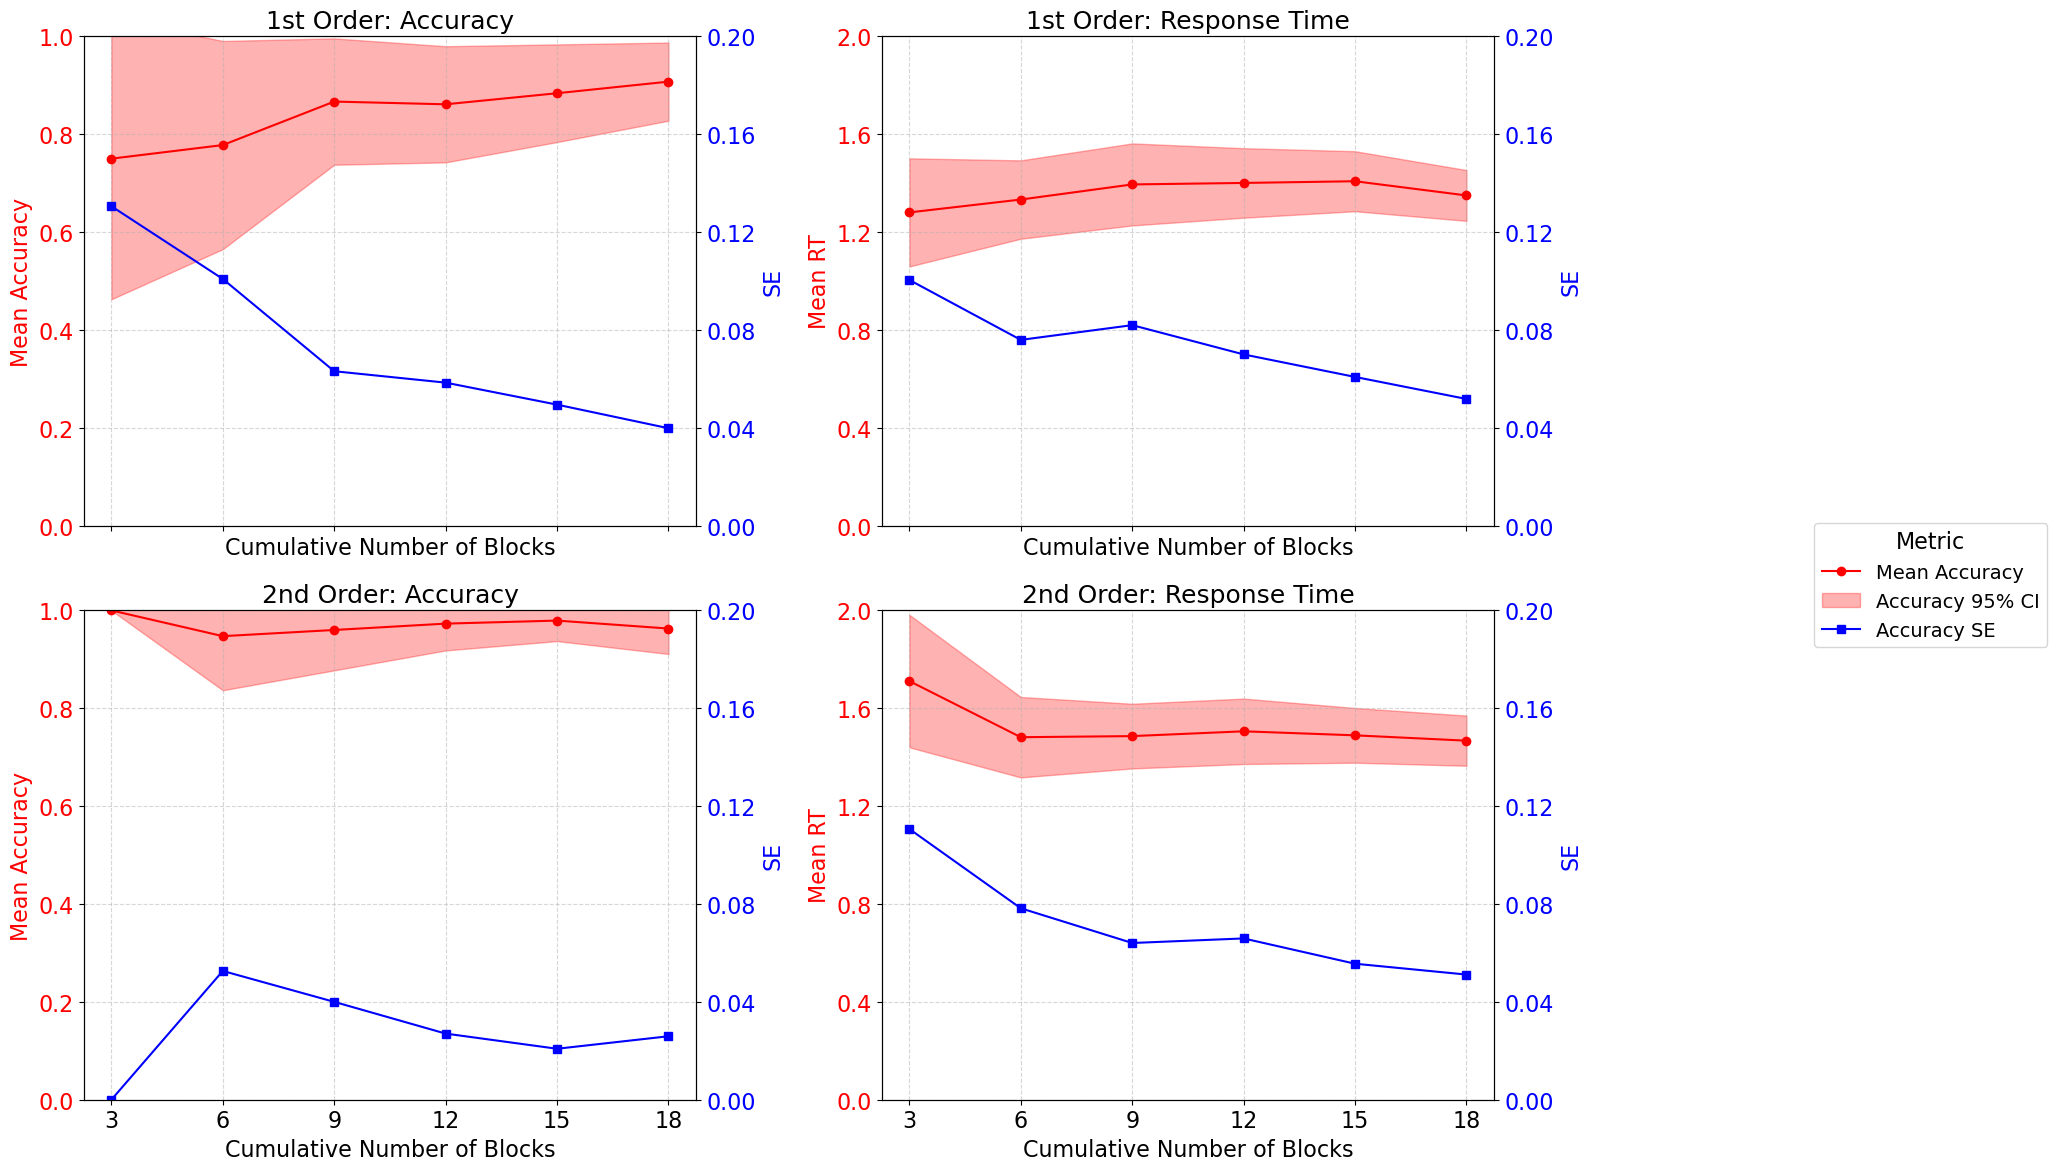

In [7]:
# ============================================================
# DROP-IN PLOTTING CODE:
# 4-panel behavioral power-analysis figure from summary_df
#
# Expects:
#   - summary_df already in memory
#   - summary_df columns:
#       ['cond', 'accuracy_mean', 'rt_mean', 'accuracy_count', 'rt_count',
#        'accuracy_sem', 'rt_sem', 'block_count', 'accuracy_ci95', 'rt_ci95']
#
# Layout:
#   Top-left:    1st Order Accuracy + SE
#   Top-right:   1st Order RT + SE
#   Bottom-left: 2nd Order Accuracy + SE
#   Bottom-right:2nd Order RT + SE
#
# Notes:
#   - This follows the style of your previous beta/SE plotting code.
#   - Mean values are plotted with 95% CI bands.
#   - SE values are plotted on the secondary y-axis.
#   - Because summary_df does not include CI bounds for the SE itself,
#     this code plots the SE line without an SE CI ribbon.
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------
# Prepare data
# ----------------------------
plot_df = summary_df.copy().sort_values(['cond', 'block_count']).reset_index(drop=True)

# Create CI bounds for means in the full dataframe FIRST
plot_df['accuracy_ci_lower'] = plot_df['accuracy_mean'] - plot_df['accuracy_ci95']
plot_df['accuracy_ci_upper'] = plot_df['accuracy_mean'] + plot_df['accuracy_ci95']
plot_df['rt_ci_lower'] = plot_df['rt_mean'] - plot_df['rt_ci95']
plot_df['rt_ci_upper'] = plot_df['rt_mean'] + plot_df['rt_ci95']

# Split by condition
cond1_df = plot_df[plot_df['cond'] == 1].copy()  # 1st order
cond2_df = plot_df[plot_df['cond'] == 2].copy()  # 2nd order

# Shared x ticks
x_ticks = sorted(plot_df['block_count'].unique())

# ----------------------------
# Plot
# ----------------------------
import numpy as np
plt.rcParams.update({'font.size': 16})

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharex=True)

# Common y-axis limits and ticks
acc_ylim = (0.0, 1.0)
rt_ylim = (0.0, 2.0)
se_ylim = (0.0, 0.2)

acc_yticks = np.linspace(acc_ylim[0], acc_ylim[1], 6)
rt_yticks = np.linspace(rt_ylim[0], rt_ylim[1], 6)
se_yticks = np.linspace(se_ylim[0], se_ylim[1], 6)

# ============================================================
# Top-left: 1st Order Accuracy + SE
# ============================================================
ax1 = axes[0, 0]
ax1.plot(cond1_df['block_count'], cond1_df['accuracy_mean'], 'o-', color='red', label='Mean Accuracy')
ax1.fill_between(cond1_df['block_count'],
                 cond1_df['accuracy_ci_lower'],
                 cond1_df['accuracy_ci_upper'],
                 color='red', alpha=0.3, label='Accuracy 95% CI')
ax1.set_title('1st Order: Accuracy', fontsize=18)
ax1.set_xlabel('Cumulative Number of Blocks', fontsize=16)
ax1.set_ylabel('Mean Accuracy', fontsize=16, color='red')
ax1.tick_params(axis='y', labelcolor='red')
ax1.set_xticks(x_ticks)
ax1.set_ylim(acc_ylim)
ax1.set_yticks(acc_yticks)
ax1.grid(True, linestyle='--', alpha=0.5)

ax1b = ax1.twinx()
ax1b.plot(cond1_df['block_count'], cond1_df['accuracy_sem'], 's-', color='blue', label='Accuracy SE')
ax1b.set_ylabel('SE', fontsize=16, color='blue')
ax1b.tick_params(axis='y', labelcolor='blue')
ax1b.set_ylim(se_ylim)
ax1b.set_yticks(se_yticks)

# ============================================================
# Top-right: 1st Order RT + SE
# ============================================================
ax2 = axes[0, 1]
ax2.plot(cond1_df['block_count'], cond1_df['rt_mean'], 'o-', color='red', label='Mean RT')
ax2.fill_between(cond1_df['block_count'],
                 cond1_df['rt_ci_lower'],
                 cond1_df['rt_ci_upper'],
                 color='red', alpha=0.3, label='RT 95% CI')
ax2.set_title('1st Order: Response Time', fontsize=18)
ax2.set_xlabel('Cumulative Number of Blocks', fontsize=16)
ax2.set_ylabel('Mean RT', fontsize=16, color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_xticks(x_ticks)
ax2.set_ylim(rt_ylim)
ax2.set_yticks(rt_yticks)
ax2.grid(True, linestyle='--', alpha=0.5)

ax2b = ax2.twinx()
ax2b.plot(cond1_df['block_count'], cond1_df['rt_sem'], 's-', color='blue', label='RT SE')
ax2b.set_ylabel('SE', fontsize=16, color='blue')
ax2b.tick_params(axis='y', labelcolor='blue')
ax2b.set_ylim(se_ylim)
ax2b.set_yticks(se_yticks)

# ============================================================
# Bottom-left: 2nd Order Accuracy + SE
# ============================================================
ax3 = axes[1, 0]
ax3.plot(cond2_df['block_count'], cond2_df['accuracy_mean'], 'o-', color='red', label='Mean Accuracy')
ax3.fill_between(cond2_df['block_count'],
                 cond2_df['accuracy_ci_lower'],
                 cond2_df['accuracy_ci_upper'],
                 color='red', alpha=0.3, label='Accuracy 95% CI')
ax3.set_title('2nd Order: Accuracy', fontsize=18)
ax3.set_xlabel('Cumulative Number of Blocks', fontsize=16)
ax3.set_ylabel('Mean Accuracy', fontsize=16, color='red')
ax3.tick_params(axis='y', labelcolor='red')
ax3.set_xticks(x_ticks)
ax3.set_ylim(acc_ylim)
ax3.set_yticks(acc_yticks)
ax3.grid(True, linestyle='--', alpha=0.5)

ax3b = ax3.twinx()
ax3b.plot(cond2_df['block_count'], cond2_df['accuracy_sem'], 's-', color='blue', label='Accuracy SE')
ax3b.set_ylabel('SE', fontsize=16, color='blue')
ax3b.tick_params(axis='y', labelcolor='blue')
ax3b.set_ylim(se_ylim)
ax3b.set_yticks(se_yticks)

# ============================================================
# Bottom-right: 2nd Order RT + SE
# ============================================================
ax4 = axes[1, 1]
ax4.plot(cond2_df['block_count'], cond2_df['rt_mean'], 'o-', color='red', label='Mean RT')
ax4.fill_between(cond2_df['block_count'],
                 cond2_df['rt_ci_lower'],
                 cond2_df['rt_ci_upper'],
                 color='red', alpha=0.3, label='RT 95% CI')
ax4.set_title('2nd Order: Response Time', fontsize=18)
ax4.set_xlabel('Cumulative Number of Blocks', fontsize=16)
ax4.set_ylabel('Mean RT', fontsize=16, color='red')
ax4.tick_params(axis='y', labelcolor='red')
ax4.set_xticks(x_ticks)
ax4.set_ylim(rt_ylim)
ax4.set_yticks(rt_yticks)
ax4.grid(True, linestyle='--', alpha=0.5)

ax4b = ax4.twinx()
ax4b.plot(cond2_df['block_count'], cond2_df['rt_sem'], 's-', color='blue', label='RT SE')
ax4b.set_ylabel('SE', fontsize=16, color='blue')
ax4b.tick_params(axis='y', labelcolor='blue')
ax4b.set_ylim(se_ylim)
ax4b.set_yticks(se_yticks)
# ----------------------------
# Shared legend
# ----------------------------
handles = (
    ax1.get_legend_handles_labels()[0] +
    ax1b.get_legend_handles_labels()[0]
)
labels = (
    ax1.get_legend_handles_labels()[1] +
    ax1b.get_legend_handles_labels()[1]
)

fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5),
           fontsize=14, title='Metric')

plt.tight_layout(rect=[0, 0, 0.90, 1])

# ----------------------------
# Save figure
# ----------------------------
save_path = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Figures\behavior_accuracy_rt_se_plot.png"  # <-- EDIT IF NEEDED
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"📁 Figure saved as: {save_path}")

plt.show()

📁 Figure saved as: C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Figures\behavior_binned_accuracy_rt_se_plot.png


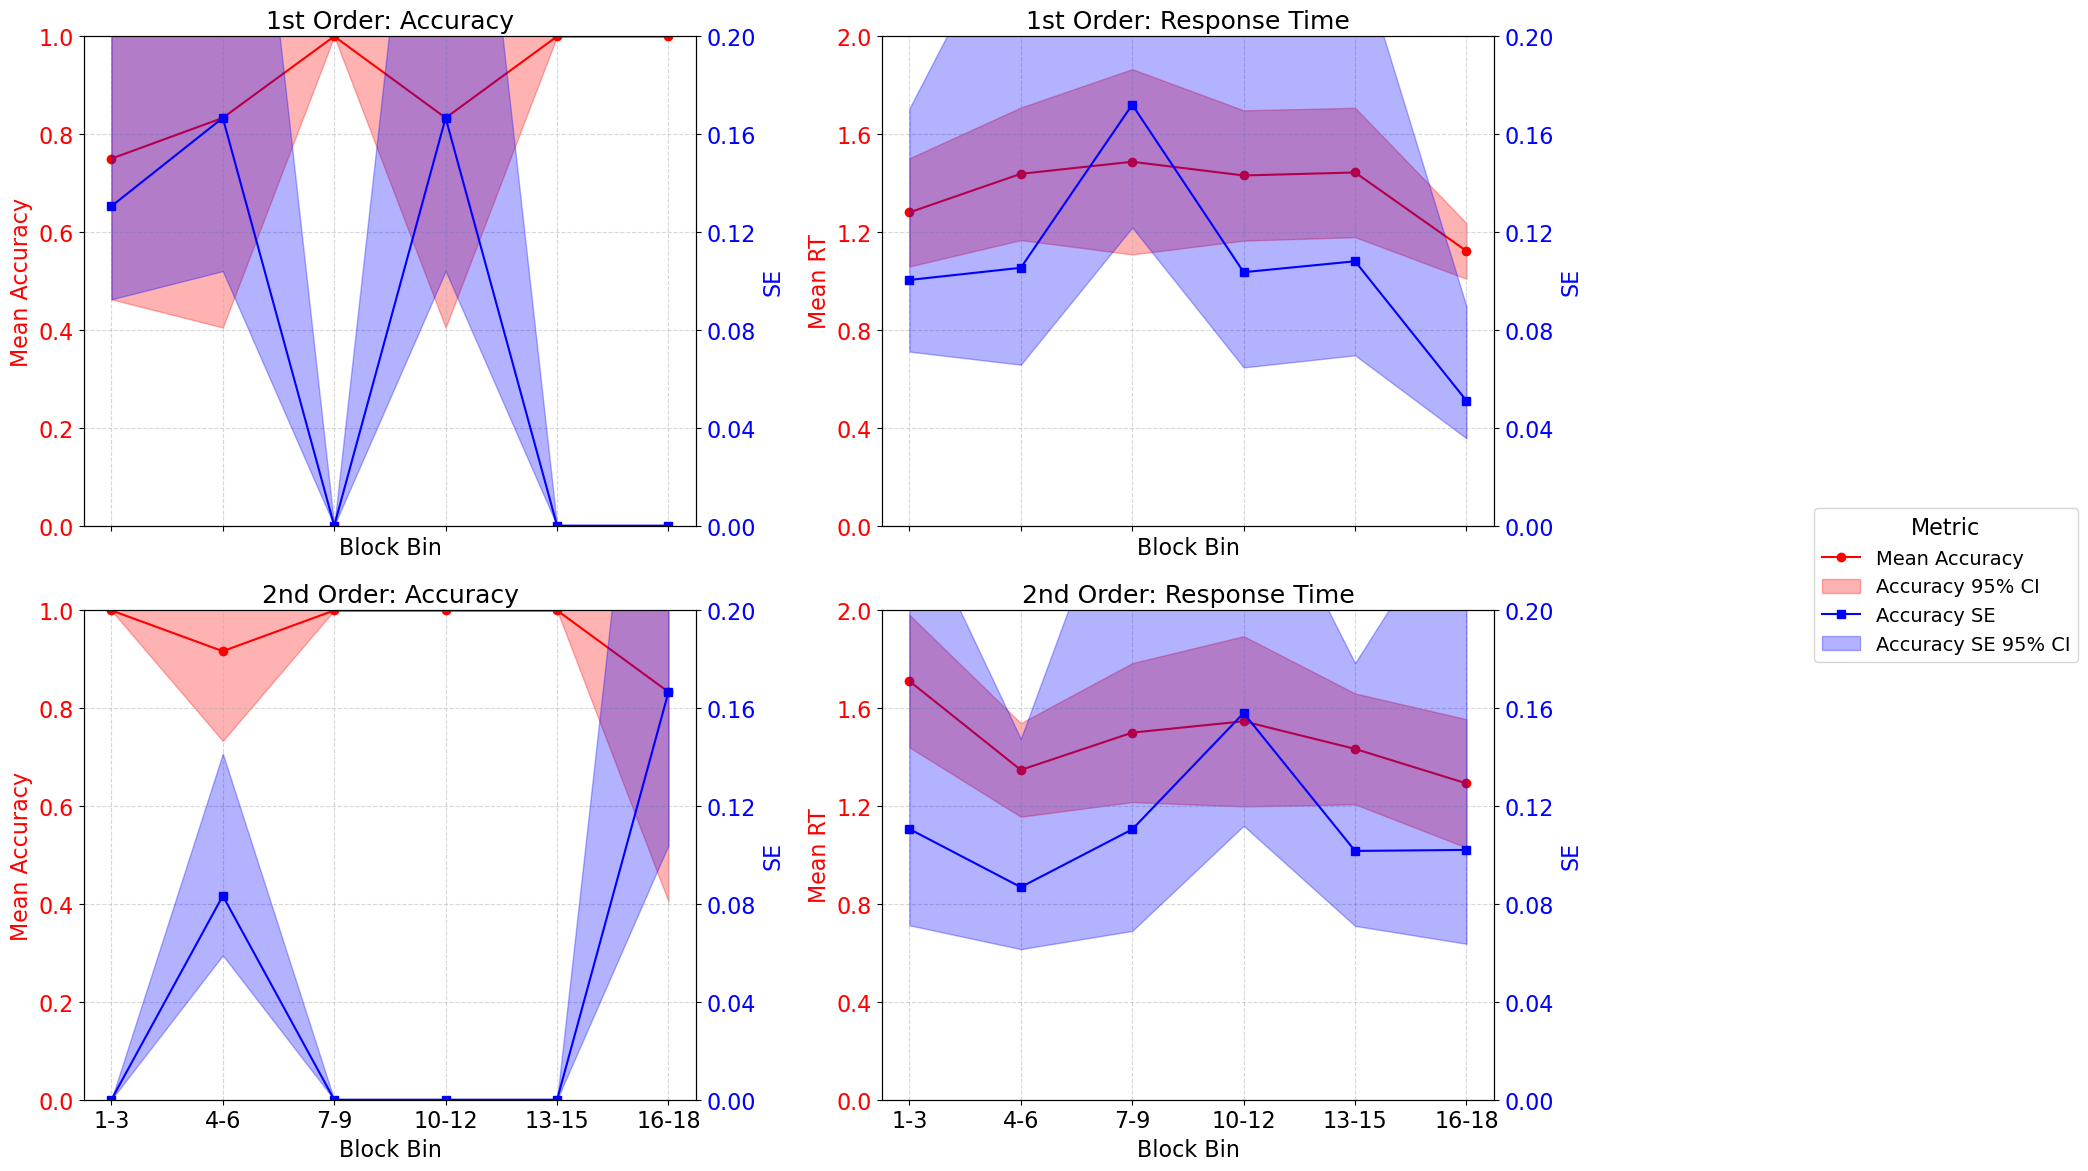

    cond  accuracy_mean   rt_mean  accuracy_count  rt_count  accuracy_sem  \
0    1.0       0.750000  1.280310              12        12      0.130558   
1    1.0       0.833333  1.438081               6         6      0.166667   
2    1.0       1.000000  1.487326              12        12      0.000000   
3    1.0       0.833333  1.431253               6         6      0.166667   
4    1.0       1.000000  1.443565               7         7      0.000000   
5    1.0       1.000000  1.122557              11        11      0.000000   
6    2.0       1.000000  1.711146               7         7      0.000000   
7    2.0       0.916667  1.347904              12        12      0.083333   
8    2.0       1.000000  1.500439               6         6      0.000000   
9    2.0       1.000000  1.546753              12        12      0.000000   
10   2.0       1.000000  1.433918              11        11      0.000000   
11   2.0       0.833333  1.292906               6         6      0.166667   

In [9]:
## Behavioral Power Analysis x3 (Binned, Non-Cumulative)
## Plots separate 3-block bins: 1–3, 4–6, 7–9, 10–12, 13–15, 16–18
## Top row = 1st Order (Accuracy+SE, RT+SE)
## Bottom row = 2nd Order (Accuracy+SE, RT+SE)

import os
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# --- Setup ---
data_dir = r'C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\behavioral data\data'

# --- Initialize master dataframe ---
all_data = []

# --- Load and combine data ---
for file in os.listdir(data_dir):
    if file.endswith('.csv'):
        df = pd.read_csv(os.path.join(data_dir, file))
        df['participant'] = os.path.splitext(file)[0]
        all_data.append(df)

full_data = pd.concat(all_data, ignore_index=True)

# --- Convert relevant columns to numeric safely ---
full_data['thisRow.t'] = pd.to_numeric(full_data['thisRow.t'], errors='coerce')
full_data['key_resp_2.corr'] = pd.to_numeric(full_data['key_resp_2.corr'], errors='coerce')
full_data['key_resp_2.rt'] = pd.to_numeric(full_data['key_resp_2.rt'], errors='coerce')
full_data['cond'] = pd.to_numeric(full_data['cond'], errors='coerce')

# --- Define condition labels ---
cond_labels = {1: '1st Order', 2: '2nd Order'}

# --- Mapping of cumulative row count to block count ---
row_cutoffs = {
    3: 56,
    6: 77,
    9: 100,
    12: 121,
    15: 142,
    18: 162
}

# --- Convert cumulative row cutoffs into separate 3-block bins ---
#     1-3  = rows   0:56
#     4-6  = rows  56:77
#     7-9  = rows  77:100
#     etc.
sorted_blocks = sorted(row_cutoffs.keys())
bin_ranges = []
prev_limit = 0

for end_block in sorted_blocks:
    row_limit = row_cutoffs[end_block]
    start_block = end_block - 2
    bin_ranges.append({
        'bin_start_block': start_block,
        'bin_end_block': end_block,
        'bin_label': f'{start_block}-{end_block}',
        'start_row': prev_limit,
        'end_row': row_limit
    })
    prev_limit = row_limit

# --- Helper function: 95% CI for SEM ---
def sem_ci_bounds(x, alpha=0.05):
    x = pd.Series(x).dropna()
    n = len(x)

    if n < 2:
        return pd.Series({
            'sem': np.nan,
            'sem_ci95_lower': np.nan,
            'sem_ci95_upper': np.nan,
            'sem_ci95_halfwidth': np.nan
        })

    s = np.std(x, ddof=1)
    sem = s / np.sqrt(n)

    chi2_lower = stats.chi2.ppf(alpha / 2, n - 1)
    chi2_upper = stats.chi2.ppf(1 - alpha / 2, n - 1)

    sd_ci_lower = np.sqrt((n - 1) * s**2 / chi2_upper)
    sd_ci_upper = np.sqrt((n - 1) * s**2 / chi2_lower)

    sem_ci_lower = sd_ci_lower / np.sqrt(n)
    sem_ci_upper = sd_ci_upper / np.sqrt(n)
    sem_ci_halfwidth = (sem_ci_upper - sem_ci_lower) / 2

    return pd.Series({
        'sem': sem,
        'sem_ci95_lower': sem_ci_lower,
        'sem_ci95_upper': sem_ci_upper,
        'sem_ci95_halfwidth': sem_ci_halfwidth
    })

# --- Store summaries for each bin ---
all_summaries = []

# --- Loop through each separate 3-block bin ---
for bin_info in bin_ranges:
    subset = full_data.iloc[bin_info['start_row']:bin_info['end_row']].copy()

    if subset.empty or 'cond' not in subset.columns:
        print(f"⚠️ No valid data for bin {bin_info['bin_label']}. Skipping.")
        continue

    summary = subset.groupby('cond').agg(
        accuracy_mean=('key_resp_2.corr', 'mean'),
        rt_mean=('key_resp_2.rt', 'mean'),
        accuracy_count=('key_resp_2.corr', 'count'),
        rt_count=('key_resp_2.rt', 'count'),
        accuracy_sem=('key_resp_2.corr', lambda x: stats.sem(x, nan_policy='omit')),
        rt_sem=('key_resp_2.rt', lambda x: stats.sem(x, nan_policy='omit'))
    ).reset_index()

    # --- Calculate 95% CI bounds for SEM for accuracy and RT ---
    accuracy_sem_ci = subset.groupby('cond')['key_resp_2.corr'].apply(sem_ci_bounds).unstack().reset_index()
    accuracy_sem_ci = accuracy_sem_ci.rename(columns={
        'sem': 'accuracy_sem_check',
        'sem_ci95_lower': 'accuracy_sem_ci95_lower',
        'sem_ci95_upper': 'accuracy_sem_ci95_upper',
        'sem_ci95_halfwidth': 'accuracy_sem_ci95_halfwidth'
    })

    rt_sem_ci = subset.groupby('cond')['key_resp_2.rt'].apply(sem_ci_bounds).unstack().reset_index()
    rt_sem_ci = rt_sem_ci.rename(columns={
        'sem': 'rt_sem_check',
        'sem_ci95_lower': 'rt_sem_ci95_lower',
        'sem_ci95_upper': 'rt_sem_ci95_upper',
        'sem_ci95_halfwidth': 'rt_sem_ci95_halfwidth'
    })

    summary = summary.merge(accuracy_sem_ci, on='cond', how='left')
    summary = summary.merge(rt_sem_ci, on='cond', how='left')

    # --- Add metadata for plotting ---
    summary['block_count'] = bin_info['bin_end_block']       # numeric x position: 3,6,9,...
    summary['block_bin'] = bin_info['bin_label']             # label: 1-3, 4-6, ...
    summary['bin_start_block'] = bin_info['bin_start_block']
    summary['bin_end_block'] = bin_info['bin_end_block']

    # --- 95% CI for mean accuracy and RT ---
    summary['accuracy_ci95'] = summary['accuracy_sem'] * stats.t.ppf(0.975, summary['accuracy_count'] - 1)
    summary['rt_ci95'] = summary['rt_sem'] * stats.t.ppf(0.975, summary['rt_count'] - 1)

    all_summaries.append(summary)

# --- Combine all summaries ---
summary_df = pd.concat(all_summaries, ignore_index=True)

# --- Create CI bounds for means in the full dataframe ---
summary_df = summary_df.sort_values(['cond', 'block_count']).reset_index(drop=True)
summary_df['accuracy_ci_lower'] = summary_df['accuracy_mean'] - summary_df['accuracy_ci95']
summary_df['accuracy_ci_upper'] = summary_df['accuracy_mean'] + summary_df['accuracy_ci95']
summary_df['rt_ci_lower'] = summary_df['rt_mean'] - summary_df['rt_ci95']
summary_df['rt_ci_upper'] = summary_df['rt_mean'] + summary_df['rt_ci95']

# --- Split by condition ---
cond1_df = summary_df[summary_df['cond'] == 1].copy()  # 1st order
cond2_df = summary_df[summary_df['cond'] == 2].copy()  # 2nd order

# --- X-axis setup ---
x_ticks = sorted(summary_df['block_count'].unique())
x_tick_labels = (
    summary_df[['block_count', 'block_bin']]
    .drop_duplicates()
    .sort_values('block_count')['block_bin']
    .tolist()
)

# --- Plot styling ---
import numpy as np
plt.rcParams.update({'font.size': 16})

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharex=True)

# Common y-axis limits and ticks
acc_ylim = (0.0, 1.0)
rt_ylim = (0.0, 2.0)
se_ylim = (0.0, 0.2)

acc_yticks = np.linspace(acc_ylim[0], acc_ylim[1], 6)
rt_yticks = np.linspace(rt_ylim[0], rt_ylim[1], 6)
se_yticks = np.linspace(se_ylim[0], se_ylim[1], 6)

# ============================================================
# Top-left: 1st Order Accuracy + SE
# ============================================================
ax1 = axes[0, 0]
ax1.plot(cond1_df['block_count'], cond1_df['accuracy_mean'], 'o-', color='red', label='Mean Accuracy')
ax1.fill_between(cond1_df['block_count'],
                 cond1_df['accuracy_ci_lower'],
                 cond1_df['accuracy_ci_upper'],
                 color='red', alpha=0.3, label='Accuracy 95% CI')
ax1.set_title('1st Order: Accuracy', fontsize=18)
ax1.set_xlabel('Block Bin', fontsize=16)
ax1.set_ylabel('Mean Accuracy', fontsize=16, color='red')
ax1.tick_params(axis='y', labelcolor='red')
ax1.set_xticks(x_ticks)
ax1.set_xticklabels(x_tick_labels)
ax1.set_ylim(acc_ylim)
ax1.set_yticks(acc_yticks)
ax1.grid(True, linestyle='--', alpha=0.5)

ax1b = ax1.twinx()
ax1b.plot(cond1_df['block_count'], cond1_df['accuracy_sem'], 's-', color='blue', label='Accuracy SE')
ax1b.fill_between(cond1_df['block_count'],
                  cond1_df['accuracy_sem_ci95_lower'],
                  cond1_df['accuracy_sem_ci95_upper'],
                  color='blue', alpha=0.3, label='Accuracy SE 95% CI')
ax1b.set_ylabel('SE', fontsize=16, color='blue')
ax1b.tick_params(axis='y', labelcolor='blue')
ax1b.set_ylim(se_ylim)
ax1b.set_yticks(se_yticks)

# ============================================================
# Top-right: 1st Order RT + SE
# ============================================================
ax2 = axes[0, 1]
ax2.plot(cond1_df['block_count'], cond1_df['rt_mean'], 'o-', color='red', label='Mean RT')
ax2.fill_between(cond1_df['block_count'],
                 cond1_df['rt_ci_lower'],
                 cond1_df['rt_ci_upper'],
                 color='red', alpha=0.3, label='RT 95% CI')
ax2.set_title('1st Order: Response Time', fontsize=18)
ax2.set_xlabel('Block Bin', fontsize=16)
ax2.set_ylabel('Mean RT', fontsize=16, color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_xticks(x_ticks)
ax2.set_xticklabels(x_tick_labels)
ax2.set_ylim(rt_ylim)
ax2.set_yticks(rt_yticks)
ax2.grid(True, linestyle='--', alpha=0.5)

ax2b = ax2.twinx()
ax2b.plot(cond1_df['block_count'], cond1_df['rt_sem'], 's-', color='blue', label='RT SE')
ax2b.fill_between(cond1_df['block_count'],
                  cond1_df['rt_sem_ci95_lower'],
                  cond1_df['rt_sem_ci95_upper'],
                  color='blue', alpha=0.3, label='RT SE 95% CI')
ax2b.set_ylabel('SE', fontsize=16, color='blue')
ax2b.tick_params(axis='y', labelcolor='blue')
ax2b.set_ylim(se_ylim)
ax2b.set_yticks(se_yticks)

# ============================================================
# Bottom-left: 2nd Order Accuracy + SE
# ============================================================
ax3 = axes[1, 0]
ax3.plot(cond2_df['block_count'], cond2_df['accuracy_mean'], 'o-', color='red', label='Mean Accuracy')
ax3.fill_between(cond2_df['block_count'],
                 cond2_df['accuracy_ci_lower'],
                 cond2_df['accuracy_ci_upper'],
                 color='red', alpha=0.3, label='Accuracy 95% CI')
ax3.set_title('2nd Order: Accuracy', fontsize=18)
ax3.set_xlabel('Block Bin', fontsize=16)
ax3.set_ylabel('Mean Accuracy', fontsize=16, color='red')
ax3.tick_params(axis='y', labelcolor='red')
ax3.set_xticks(x_ticks)
ax3.set_xticklabels(x_tick_labels)
ax3.set_ylim(acc_ylim)
ax3.set_yticks(acc_yticks)
ax3.grid(True, linestyle='--', alpha=0.5)

ax3b = ax3.twinx()
ax3b.plot(cond2_df['block_count'], cond2_df['accuracy_sem'], 's-', color='blue', label='Accuracy SE')
ax3b.fill_between(cond2_df['block_count'],
                  cond2_df['accuracy_sem_ci95_lower'],
                  cond2_df['accuracy_sem_ci95_upper'],
                  color='blue', alpha=0.3, label='Accuracy SE 95% CI')
ax3b.set_ylabel('SE', fontsize=16, color='blue')
ax3b.tick_params(axis='y', labelcolor='blue')
ax3b.set_ylim(se_ylim)
ax3b.set_yticks(se_yticks)

# ============================================================
# Bottom-right: 2nd Order RT + SE
# ============================================================
ax4 = axes[1, 1]
ax4.plot(cond2_df['block_count'], cond2_df['rt_mean'], 'o-', color='red', label='Mean RT')
ax4.fill_between(cond2_df['block_count'],
                 cond2_df['rt_ci_lower'],
                 cond2_df['rt_ci_upper'],
                 color='red', alpha=0.3, label='RT 95% CI')
ax4.set_title('2nd Order: Response Time', fontsize=18)
ax4.set_xlabel('Block Bin', fontsize=16)
ax4.set_ylabel('Mean RT', fontsize=16, color='red')
ax4.tick_params(axis='y', labelcolor='red')
ax4.set_xticks(x_ticks)
ax4.set_xticklabels(x_tick_labels)
ax4.set_ylim(rt_ylim)
ax4.set_yticks(rt_yticks)
ax4.grid(True, linestyle='--', alpha=0.5)

ax4b = ax4.twinx()
ax4b.plot(cond2_df['block_count'], cond2_df['rt_sem'], 's-', color='blue', label='RT SE')
ax4b.fill_between(cond2_df['block_count'],
                  cond2_df['rt_sem_ci95_lower'],
                  cond2_df['rt_sem_ci95_upper'],
                  color='blue', alpha=0.3, label='RT SE 95% CI')
ax4b.set_ylabel('SE', fontsize=16, color='blue')
ax4b.tick_params(axis='y', labelcolor='blue')
ax4b.set_ylim(se_ylim)
ax4b.set_yticks(se_yticks)

# ----------------------------
# Shared legend
# ----------------------------
handles = (
    ax1.get_legend_handles_labels()[0] +
    ax1b.get_legend_handles_labels()[0]
)
legend_labels = (
    ax1.get_legend_handles_labels()[1] +
    ax1b.get_legend_handles_labels()[1]
)

fig.legend(handles, legend_labels, loc='center left', bbox_to_anchor=(1.01, 0.5),
           fontsize=14, title='Metric')

plt.tight_layout(rect=[0, 0, 0.90, 1])

# ----------------------------
# Save figure
# ----------------------------
save_path = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Figures\behavior_binned_accuracy_rt_se_plot.png"  # <-- EDIT IF NEEDED
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"📁 Figure saved as: {save_path}")

plt.show()

# --- Optional: inspect the updated binned summary dataframe ---
print(summary_df)

📁 Figure saved as: C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Figures\behavior_binned_noCI_plot.png


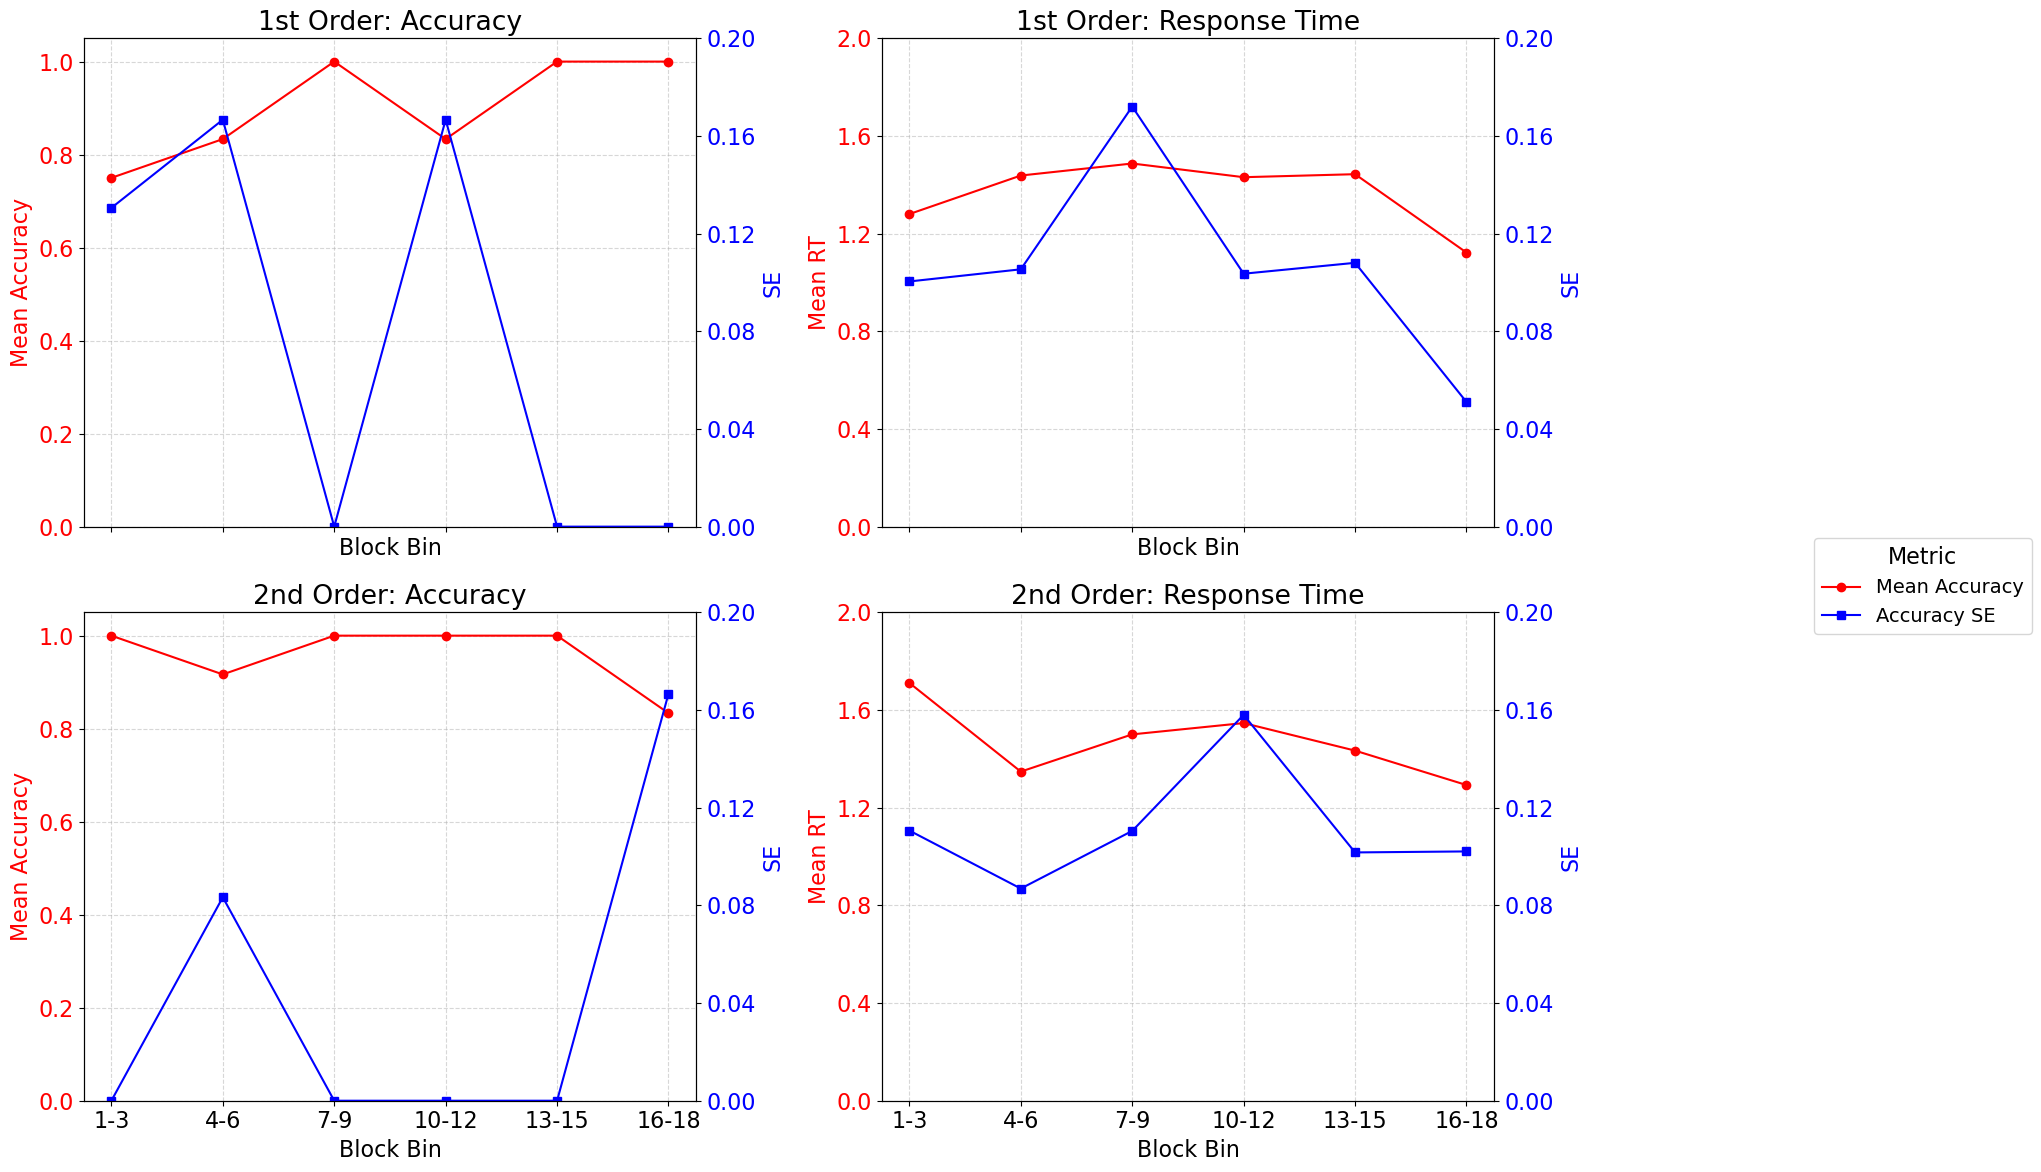

In [19]:
## Behavioral Power Analysis x3 (Binned, Non-Cumulative, NO CI BANDS)

import os
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# --- Setup ---
data_dir = r'C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\behavioral data\data'

# --- Initialize master dataframe ---
all_data = []

# --- Load and combine data ---
for file in os.listdir(data_dir):
    if file.endswith('.csv'):
        df = pd.read_csv(os.path.join(data_dir, file))
        df['participant'] = os.path.splitext(file)[0]
        all_data.append(df)

full_data = pd.concat(all_data, ignore_index=True)

# --- Convert relevant columns to numeric safely ---
full_data['thisRow.t'] = pd.to_numeric(full_data['thisRow.t'], errors='coerce')
full_data['key_resp_2.corr'] = pd.to_numeric(full_data['key_resp_2.corr'], errors='coerce')
full_data['key_resp_2.rt'] = pd.to_numeric(full_data['key_resp_2.rt'], errors='coerce')
full_data['cond'] = pd.to_numeric(full_data['cond'], errors='coerce')

# --- Mapping of cumulative row count to block count ---
row_cutoffs = {
    3: 56,
    6: 77,
    9: 100,
    12: 121,
    15: 142,
    18: 162
}

# --- Convert cumulative to bins ---
sorted_blocks = sorted(row_cutoffs.keys())
bin_ranges = []
prev_limit = 0

for end_block in sorted_blocks:
    row_limit = row_cutoffs[end_block]
    start_block = end_block - 2
    bin_ranges.append({
        'bin_start_block': start_block,
        'bin_end_block': end_block,
        'bin_label': f'{start_block}-{end_block}',
        'start_row': prev_limit,
        'end_row': row_limit
    })
    prev_limit = row_limit

# --- Store summaries ---
all_summaries = []

for bin_info in bin_ranges:
    subset = full_data.iloc[bin_info['start_row']:bin_info['end_row']].copy()

    if subset.empty or 'cond' not in subset.columns:
        continue

    summary = subset.groupby('cond').agg(
        accuracy_mean=('key_resp_2.corr', 'mean'),
        rt_mean=('key_resp_2.rt', 'mean'),
        accuracy_sem=('key_resp_2.corr', lambda x: stats.sem(x, nan_policy='omit')),
        rt_sem=('key_resp_2.rt', lambda x: stats.sem(x, nan_policy='omit'))
    ).reset_index()

    summary['block_count'] = bin_info['bin_end_block']
    summary['block_bin'] = bin_info['bin_label']

    all_summaries.append(summary)

summary_df = pd.concat(all_summaries, ignore_index=True)
summary_df = summary_df.sort_values(['cond', 'block_count']).reset_index(drop=True)

# --- Split by condition ---
cond1_df = summary_df[summary_df['cond'] == 1].copy()
cond2_df = summary_df[summary_df['cond'] == 2].copy()

# --- X-axis ---
x_ticks = sorted(summary_df['block_count'].unique())
x_tick_labels = (
    summary_df[['block_count', 'block_bin']]
    .drop_duplicates()
    .sort_values('block_count')['block_bin']
    .tolist()
)

# --- Plot ---
import numpy as np
plt.rcParams.update({'font.size': 16})
fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharex=True)

# --- Common axis settings ---
# Accuracy: small padding below 0 and above 1, but top tick remains 1.0
acc_ylim = (-0.00, 1.05)
acc_yticks = np.linspace(0.0, 1.0, 6)

# RT: fixed range
rt_ylim = (0.0, 2.0)
rt_yticks = np.linspace(0.0, 2.0, 6)

# SE: fixed range with evenly spaced ticks
se_ylim = (0.0, 0.2)
se_yticks = np.linspace(0.0, 0.2, 6)

# === 1st Order Accuracy ===
ax1 = axes[0, 0]
ax1.plot(cond1_df['block_count'], cond1_df['accuracy_mean'], 'o-', color='red', label='Mean Accuracy')
ax1.set_title('1st Order: Accuracy')
ax1.set_xlabel('Block Bin')
ax1.set_ylabel('Mean Accuracy', color='red')
ax1.tick_params(axis='y', labelcolor='red')
ax1.set_xticks(x_ticks)
ax1.set_xticklabels(x_tick_labels)
ax1.set_ylim(acc_ylim)
ax1.set_yticks(acc_yticks)
ax1.grid(True, linestyle='--', alpha=0.5)

ax1b = ax1.twinx()
ax1b.plot(cond1_df['block_count'], cond1_df['accuracy_sem'], 's-', color='blue', label='Accuracy SE')
ax1b.set_ylabel('SE', color='blue')
ax1b.tick_params(axis='y', labelcolor='blue')
ax1b.set_ylim(se_ylim)
ax1b.set_yticks(se_yticks)

# === 1st Order RT ===
ax2 = axes[0, 1]
ax2.plot(cond1_df['block_count'], cond1_df['rt_mean'], 'o-', color='red', label='Mean RT')
ax2.set_title('1st Order: Response Time')
ax2.set_xlabel('Block Bin')
ax2.set_ylabel('Mean RT', color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_xticks(x_ticks)
ax2.set_xticklabels(x_tick_labels)
ax2.set_ylim(rt_ylim)
ax2.set_yticks(rt_yticks)
ax2.grid(True, linestyle='--', alpha=0.5)

ax2b = ax2.twinx()
ax2b.plot(cond1_df['block_count'], cond1_df['rt_sem'], 's-', color='blue', label='RT SE')
ax2b.set_ylabel('SE', color='blue')
ax2b.tick_params(axis='y', labelcolor='blue')
ax2b.set_ylim(se_ylim)
ax2b.set_yticks(se_yticks)

# === 2nd Order Accuracy ===
ax3 = axes[1, 0]
ax3.plot(cond2_df['block_count'], cond2_df['accuracy_mean'], 'o-', color='red', label='Mean Accuracy')
ax3.set_title('2nd Order: Accuracy')
ax3.set_xlabel('Block Bin')
ax3.set_ylabel('Mean Accuracy', color='red')
ax3.tick_params(axis='y', labelcolor='red')
ax3.set_xticks(x_ticks)
ax3.set_xticklabels(x_tick_labels)
ax3.set_ylim(acc_ylim)
ax3.set_yticks(acc_yticks)
ax3.grid(True, linestyle='--', alpha=0.5)

ax3b = ax3.twinx()
ax3b.plot(cond2_df['block_count'], cond2_df['accuracy_sem'], 's-', color='blue', label='Accuracy SE')
ax3b.set_ylabel('SE', color='blue')
ax3b.tick_params(axis='y', labelcolor='blue')
ax3b.set_ylim(se_ylim)
ax3b.set_yticks(se_yticks)

# === 2nd Order RT ===
ax4 = axes[1, 1]
ax4.plot(cond2_df['block_count'], cond2_df['rt_mean'], 'o-', color='red', label='Mean RT')
ax4.set_title('2nd Order: Response Time')
ax4.set_xlabel('Block Bin')
ax4.set_ylabel('Mean RT', color='red')
ax4.tick_params(axis='y', labelcolor='red')
ax4.set_xticks(x_ticks)
ax4.set_xticklabels(x_tick_labels)
ax4.set_ylim(rt_ylim)
ax4.set_yticks(rt_yticks)
ax4.grid(True, linestyle='--', alpha=0.5)

ax4b = ax4.twinx()
ax4b.plot(cond2_df['block_count'], cond2_df['rt_sem'], 's-', color='blue', label='RT SE')
ax4b.set_ylabel('SE', color='blue')
ax4b.tick_params(axis='y', labelcolor='blue')
ax4b.set_ylim(se_ylim)
ax4b.set_yticks(se_yticks)

# --- Legend ---
handles = ax1.get_legend_handles_labels()[0] + ax1b.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax1b.get_legend_handles_labels()[1]

fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5),
           fontsize=14, title='Metric')

plt.tight_layout(rect=[0, 0, 0.90, 1])

# --- Save ---
save_path = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Figures\behavior_binned_noCI_plot.png"
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"📁 Figure saved as: {save_path}")

plt.show()

C:\Users\pkell\anaconda3\Lib\site-packages\numpy\core\_methods.py:206: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\pkell\anaconda3\Lib\site-packages\numpy\core\_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


    cond  accuracy_mean   rt_mean  accuracy_count  rt_count  accuracy_sem  \
0    1.0       1.000000  1.106838               6         6      0.000000   
1    2.0       1.000000  2.020598               1         1           NaN   
2    1.0       0.857143  1.153859               7         7      0.142857   
3    2.0       1.000000  1.713165               6         6      0.000000   
4    1.0       0.750000  1.280310              12        12      0.130558   
5    2.0       1.000000  1.711146               7         7      0.000000   
6    1.0       0.750000  1.280310              12        12      0.130558   
7    2.0       0.923077  1.565621              13        13      0.076923   
8    1.0       0.692308  1.312291              13        13      0.133235   
9    2.0       0.944444  1.456973              18        18      0.055556   
10   1.0       0.777778  1.332900              18        18      0.100832   
11   2.0       0.947368  1.481730              19        19      0.052632   

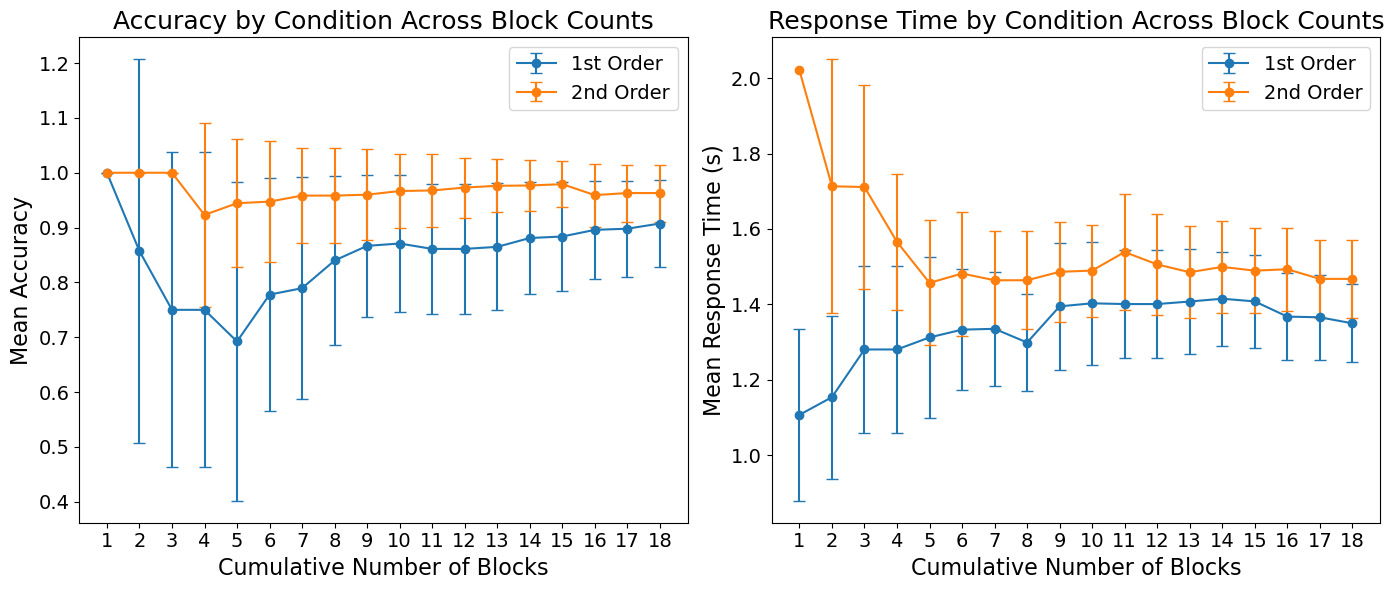

In [5]:
## Behavioral Power Analysis x1 

import os
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# --- Setup ---
data_dir = r'C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\behavioral data\data'

# --- Initialize master dataframe ---
all_data = []

# --- Load and combine data ---
for file in os.listdir(data_dir):
    if file.endswith('.csv'):
        df = pd.read_csv(os.path.join(data_dir, file))
        df['participant'] = os.path.splitext(file)[0]
        all_data.append(df)

full_data = pd.concat(all_data, ignore_index=True)

# --- Convert relevant columns to numeric safely ---
full_data['thisRow.t'] = pd.to_numeric(full_data['thisRow.t'], errors='coerce')

# --- Define condition labels ---
labels = {1: '1st Order', 2: '2nd Order'}

# --- Mapping of block count to row count ---
row_cutoffs = {
    1: 42,
    2: 49,
    3: 56,
    4: 63,
    5: 70,
    6: 77,
    7: 84,
    8: 91,
    9: 100,    
    10: 107,
    11: 114,
    12: 121,
    13: 128,
    14: 135,
    15: 142,
    16: 149,
    17: 156,
    18: 162
}

# --- Store summaries for each step ---
all_summaries = []

# --- Loop through each row cutoff ---
for block_count, row_limit in row_cutoffs.items():
    subset = full_data.iloc[:row_limit].copy()

    if subset.empty or 'cond' not in subset.columns:
        print(f"⚠️ No valid data for block count {block_count}. Skipping.")
        continue

    summary = subset.groupby('cond').agg(
        accuracy_mean=('key_resp_2.corr', 'mean'),
        rt_mean=('key_resp_2.rt', 'mean'),
        accuracy_count=('key_resp_2.corr', 'count'),
        rt_count=('key_resp_2.rt', 'count'),
        accuracy_sem=('key_resp_2.corr', lambda x: stats.sem(x, nan_policy='omit')),
        rt_sem=('key_resp_2.rt', lambda x: stats.sem(x, nan_policy='omit'))
    ).reset_index()

    summary['block_count'] = block_count
    summary['accuracy_ci95'] = summary['accuracy_sem'] * stats.t.ppf(0.975, summary['accuracy_count'] - 1)
    summary['rt_ci95'] = summary['rt_sem'] * stats.t.ppf(0.975, summary['rt_count'] - 1)

    all_summaries.append(summary)

# --- Combine all summaries ---
summary_df = pd.concat(all_summaries, ignore_index=True)
print(summary_df)

import matplotlib.pyplot as plt

# --- Plotting ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Define x-ticks for block counts
block_counts = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]

# Accuracy plot
for cond in summary_df['cond'].unique():
    data = summary_df[summary_df['cond'] == cond]
    axes[0].errorbar(data['block_count'], data['accuracy_mean'], yerr=data['accuracy_ci95'],
                     label=labels.get(cond, str(cond)), marker='o', capsize=4)
axes[0].set_title('Accuracy by Condition Across Block Counts', fontsize=18)
axes[0].set_xlabel('Cumulative Number of Blocks', fontsize=16)
axes[0].set_ylabel('Mean Accuracy', fontsize=16)
axes[0].set_xticks(block_counts)
axes[0].tick_params(axis='both', labelsize=14)
axes[0].legend(fontsize=14)
axes[0].set_facecolor('white')  # Ensure white background
axes[0].grid(False)             # Remove grid lines

# Reaction Time plot
for cond in summary_df['cond'].unique():
    data = summary_df[summary_df['cond'] == cond]
    axes[1].errorbar(data['block_count'], data['rt_mean'], yerr=data['rt_ci95'],
                     label=labels.get(cond, str(cond)), marker='o', capsize=4)
axes[1].set_title('Response Time by Condition Across Block Counts', fontsize=18)
axes[1].set_xlabel('Cumulative Number of Blocks', fontsize=16)
axes[1].set_ylabel('Mean Response Time (s)', fontsize=16)
axes[1].set_xticks(block_counts)
axes[1].tick_params(axis='both', labelsize=14)
axes[1].legend(fontsize=14)
axes[1].set_facecolor('white')  # Ensure white background
axes[1].grid(False)             # Remove grid lines

plt.tight_layout()

# --- Save figure ---
save_path = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Figures\nblocks_behavioralx1.png"  # <-- EDIT THIS PATH
plt.savefig(save_path, dpi=300)
print(f"📁 Figure saved as: {save_path}")
    
plt.show()


In [10]:
# ============================================================
# FIXED: subject-level “learning” metrics (Block 9 - Block 1)
# Blocks are defined on the FULL trial sequence per participant,
# then accuracy/RT are computed within each block slice by condition.
# ============================================================

def _get_block_slice_full(dfp: pd.DataFrame, block_k: int, row_cutoffs: dict) -> pd.DataFrame:
    """Incremental block-k slice using row_cutoffs on the FULL participant trial stream."""
    end_idx = row_cutoffs[block_k]
    start_idx = 0 if block_k == 1 else row_cutoffs[block_k - 1]
    return dfp.iloc[start_idx:end_idx].copy()

def _summ_block_cond(df_block: pd.DataFrame, cond_val: float) -> pd.Series:
    """Summarize accuracy/RT for a given condition within a block slice."""
    dfc = df_block[df_block['cond'] == cond_val]
    acc = dfc['key_resp_2.corr'].mean(skipna=True)
    rt  = dfc['key_resp_2.rt'].mean(skipna=True)
    n_acc = dfc['key_resp_2.corr'].count()
    n_rt  = dfc['key_resp_2.rt'].count()
    return pd.Series({'accuracy_mean': acc, 'rt_mean': rt, 'n_acc': n_acc, 'n_rt': n_rt})

def _pct_gt0(x: pd.Series) -> float:
    x = pd.to_numeric(x, errors='coerce').dropna()
    if len(x) == 0:
        return np.nan
    return 100.0 * (x > 0).mean()

def summarize_deltas_safe(df: pd.DataFrame, label: str) -> pd.Series:
    """Safe summary even if df is empty."""
    if df.empty:
        return pd.Series({
            'group': label,
            'n_participants_with_block9': 0,
            'delta_acc_median': np.nan,
            'delta_acc_min': np.nan,
            'delta_acc_max': np.nan,
            'delta_acc_mean': np.nan,
            'delta_acc_sd': np.nan,
            'delta_acc_pct_improved': np.nan,
            'delta_rt_median': np.nan,
            'delta_rt_min': np.nan,
            'delta_rt_max': np.nan,
            'delta_rt_mean': np.nan,
            'delta_rt_sd': np.nan,
            'delta_rt_pct_increased': np.nan
        })

    dacc = pd.to_numeric(df['delta_accuracy_b9_minus_b1'], errors='coerce').dropna()
    drt  = pd.to_numeric(df['delta_rt_b9_minus_b1'], errors='coerce').dropna()

    # If all NaN after dropna, keep safe NaNs
    def safe_stat(arr, fn):
        return fn(arr) if len(arr) > 0 else np.nan

    return pd.Series({
        'group': label,
        'n_participants_with_block9': int(df['has_block9'].sum()),
        'delta_acc_median': safe_stat(dacc, np.median),
        'delta_acc_min': safe_stat(dacc, np.min),
        'delta_acc_max': safe_stat(dacc, np.max),
        'delta_acc_mean': safe_stat(dacc, np.mean),
        'delta_acc_sd': safe_stat(dacc, lambda a: np.std(a, ddof=1) if len(a) > 1 else np.nan),
        'delta_acc_pct_improved': _pct_gt0(dacc),
        'delta_rt_median': safe_stat(drt, np.median),
        'delta_rt_min': safe_stat(drt, np.min),
        'delta_rt_max': safe_stat(drt, np.max),
        'delta_rt_mean': safe_stat(drt, np.mean),
        'delta_rt_sd': safe_stat(drt, lambda a: np.std(a, ddof=1) if len(a) > 1 else np.nan),
        'delta_rt_pct_increased': _pct_gt0(drt)  # positive = slower at block 9 vs block 1
    })

# --- Build subject-level learning df for Block 1 vs Block 9 ---
subject_rows = []

for pid, dfp in full_data.groupby('participant', sort=False):
    dfp = dfp.sort_index()

    needed = {'cond', 'key_resp_2.corr', 'key_resp_2.rt'}
    if not needed.issubset(dfp.columns):
        continue

    # must have enough total rows to define block 9 on the FULL stream
    has_b9 = int(len(dfp) >= row_cutoffs[9])

    b1 = _get_block_slice_full(dfp, 1, row_cutoffs) if len(dfp) >= row_cutoffs[1] else pd.DataFrame(columns=dfp.columns)
    b9 = _get_block_slice_full(dfp, 9, row_cutoffs) if has_b9 else pd.DataFrame(columns=dfp.columns)

    for cond in sorted(dfp['cond'].dropna().unique()):
        b1_sum = _summ_block_cond(b1, cond) if not b1.empty else pd.Series({'accuracy_mean': np.nan, 'rt_mean': np.nan, 'n_acc': 0, 'n_rt': 0})
        b9_sum = _summ_block_cond(b9, cond) if not b9.empty else pd.Series({'accuracy_mean': np.nan, 'rt_mean': np.nan, 'n_acc': 0, 'n_rt': 0})

        subject_rows.append({
            'participant': pid,
            'cond': cond,
            'block1_accuracy': b1_sum['accuracy_mean'],
            'block1_rt': b1_sum['rt_mean'],
            'block1_n_acc': int(b1_sum['n_acc']),
            'block1_n_rt': int(b1_sum['n_rt']),
            'block9_accuracy': b9_sum['accuracy_mean'],
            'block9_rt': b9_sum['rt_mean'],
            'block9_n_acc': int(b9_sum['n_acc']),
            'block9_n_rt': int(b9_sum['n_rt']),
            'delta_accuracy_b9_minus_b1': b9_sum['accuracy_mean'] - b1_sum['accuracy_mean'],
            'delta_rt_b9_minus_b1': b9_sum['rt_mean'] - b1_sum['rt_mean'],
            'has_block9': has_b9,
            'n_rows_total': int(len(dfp))
        })

subject_df = pd.DataFrame(subject_rows)

print("\n" + "="*80)
print("SUBJECT-LEVEL LEARNING METRICS (Block 9 - Block 1), blocks defined on FULL trial stream")
print("Each row = participant × condition")
print("="*80)
print(subject_df.to_string(index=False))

# --- Group summaries of deltas (now safe + should be non-empty) ---
delta_summaries = []
for cond in sorted(subject_df['cond'].dropna().unique()):
    dfc = subject_df[(subject_df['cond'] == cond) & (subject_df['has_block9'] == 1)].copy()
    delta_summaries.append(summarize_deltas_safe(dfc, f"cond={cond} ({labels.get(cond, cond)})"))

delta_summary_df = pd.DataFrame(delta_summaries)

print("\n" + "="*80)
print("GROUP-LEVEL SUMMARY OF SUBJECT DELTAS (Block 9 - Block 1)")
print("NOTE: RT direction: positive delta means slower at block 9 vs block 1.")
print("="*80)
print(delta_summary_df.to_string(index=False))

# --- Counts (direction of change) ---
counts_rows = []
for cond in sorted(subject_df['cond'].dropna().unique()):
    dfc = subject_df[(subject_df['cond'] == cond) & (subject_df['has_block9'] == 1)]
    dacc = pd.to_numeric(dfc['delta_accuracy_b9_minus_b1'], errors='coerce').dropna()
    drt  = pd.to_numeric(dfc['delta_rt_b9_minus_b1'], errors='coerce').dropna()

    counts_rows.append({
        'cond': cond,
        'label': labels.get(cond, str(cond)),
        'n_participants_with_block9': int(dfc.shape[0]),
        'acc_improved_n': int((dacc > 0).sum()),
        'acc_worsened_n': int((dacc < 0).sum()),
        'acc_nochange_n': int((dacc == 0).sum()),
        'rt_increased_n': int((drt > 0).sum()),   # slower
        'rt_decreased_n': int((drt < 0).sum()),   # faster
        'rt_nochange_n': int((drt == 0).sum())
    })

counts_df = pd.DataFrame(counts_rows)

# --- Paired t-tests: Block 9 vs Block 1 (within condition) ---
from scipy import stats

ttest_rows = []

for cond in sorted(subject_df['cond'].dropna().unique()):
    dfc = subject_df[(subject_df['cond'] == cond) & (subject_df['has_block9'] == 1)].copy()

    # Accuracy paired test
    acc_pairs = dfc[['block1_accuracy', 'block9_accuracy']].apply(pd.to_numeric, errors='coerce').dropna()
    if len(acc_pairs) >= 2:
        t_acc, p_acc = stats.ttest_rel(acc_pairs['block9_accuracy'], acc_pairs['block1_accuracy'], nan_policy='omit')
        dz_acc = (acc_pairs['block9_accuracy'] - acc_pairs['block1_accuracy']).mean() / \
                 (acc_pairs['block9_accuracy'] - acc_pairs['block1_accuracy']).std(ddof=1)
        acc_df = len(acc_pairs) - 1
    else:
        t_acc, p_acc, dz_acc, acc_df = np.nan, np.nan, np.nan, np.nan

    # RT paired test
    rt_pairs = dfc[['block1_rt', 'block9_rt']].apply(pd.to_numeric, errors='coerce').dropna()
    if len(rt_pairs) >= 2:
        t_rt, p_rt = stats.ttest_rel(rt_pairs['block9_rt'], rt_pairs['block1_rt'], nan_policy='omit')
        dz_rt = (rt_pairs['block9_rt'] - rt_pairs['block1_rt']).mean() / \
                (rt_pairs['block9_rt'] - rt_pairs['block1_rt']).std(ddof=1)
        rt_df = len(rt_pairs) - 1
    else:
        t_rt, p_rt, dz_rt, rt_df = np.nan, np.nan, np.nan, np.nan

    ttest_rows.append({
        'cond': cond,
        'label': labels.get(cond, str(cond)),
        'acc_n_pairs': len(acc_pairs),
        'acc_t': t_acc,
        'acc_df': acc_df,
        'acc_p': p_acc,
        'acc_dz': dz_acc,
        'rt_n_pairs': len(rt_pairs),
        'rt_t': t_rt,
        'rt_df': rt_df,
        'rt_p': p_rt,
        'rt_dz': dz_rt
    })

ttest_df = pd.DataFrame(ttest_rows)

print("\n" + "="*80)
print("COUNTS (direction of change across participants)")
print("="*80)
print(counts_df.to_string(index=False))

print("\n" + "="*80)
print("PAIRED T-TESTS: BLOCK 9 VS BLOCK 1")
print("Accuracy: positive t means higher accuracy at block 9.")
print("RT: positive t means slower at block 9; negative t means faster at block 9.")
print("="*80)
print(ttest_df.to_string(index=False))


SUBJECT-LEVEL LEARNING METRICS (Block 9 - Block 1), blocks defined on FULL trial stream
Each row = participant × condition
                                          participant  cond  block1_accuracy  block1_rt  block1_n_acc  block1_n_rt  block9_accuracy  block9_rt  block9_n_acc  block9_n_rt  delta_accuracy_b9_minus_b1  delta_rt_b9_minus_b1  has_block9  n_rows_total
          Allison2_rel_match3_2024-11-19_12h27.05.957   1.0         1.000000   1.106838             6            6         1.000000   1.874348             5            5                    0.000000              0.767509           1           163
          Allison2_rel_match3_2024-11-19_12h27.05.957   2.0         1.000000   2.020598             1            1         1.000000   2.022527             1            1                    0.000000              0.001929           1           163
          Allison2_rel_match3_2024-12-03_16h32.06.563   1.0         1.000000   1.193527             7            7              NaN       

In [8]:
# ============================================================
# FIXED: subject-level “learning” metrics (Block 4 - Block 1)
# Blocks are defined on the FULL trial sequence per participant,
# then accuracy/RT are computed within each block slice by condition.
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


def _get_block_slice_full(dfp: pd.DataFrame, block_k: int, row_cutoffs: dict) -> pd.DataFrame:
    """Incremental block-k slice using row_cutoffs on the FULL participant trial stream."""
    end_idx = row_cutoffs[block_k]
    start_idx = 0 if block_k == 1 else row_cutoffs[block_k - 1]
    return dfp.iloc[start_idx:end_idx].copy()

def _summ_block_cond(df_block: pd.DataFrame, cond_val: float) -> pd.Series:
    """Summarize accuracy/RT for a given condition within a block slice."""
    dfc = df_block[df_block['cond'] == cond_val]
    acc = dfc['key_resp_2.corr'].mean(skipna=True)
    rt  = dfc['key_resp_2.rt'].mean(skipna=True)
    n_acc = dfc['key_resp_2.corr'].count()
    n_rt  = dfc['key_resp_2.rt'].count()
    return pd.Series({'accuracy_mean': acc, 'rt_mean': rt, 'n_acc': n_acc, 'n_rt': n_rt})

def _pct_gt0(x: pd.Series) -> float:
    x = pd.to_numeric(x, errors='coerce').dropna()
    if len(x) == 0:
        return np.nan
    return 100.0 * (x > 0).mean()

def summarize_deltas_safe(df: pd.DataFrame, label: str) -> pd.Series:
    """Safe summary even if df is empty."""
    if df.empty:
        return pd.Series({
            'group': label,
            'n_participants_with_block4': 0,
            'delta_acc_median': np.nan,
            'delta_acc_min': np.nan,
            'delta_acc_max': np.nan,
            'delta_acc_mean': np.nan,
            'delta_acc_sd': np.nan,
            'delta_acc_pct_improved': np.nan,
            'delta_rt_median': np.nan,
            'delta_rt_min': np.nan,
            'delta_rt_max': np.nan,
            'delta_rt_mean': np.nan,
            'delta_rt_sd': np.nan,
            'delta_rt_pct_increased': np.nan
        })

    dacc = pd.to_numeric(df['delta_accuracy_b4_minus_b1'], errors='coerce').dropna()
    drt  = pd.to_numeric(df['delta_rt_b4_minus_b1'], errors='coerce').dropna()

    # If all NaN after dropna, keep safe NaNs
    def safe_stat(arr, fn):
        return fn(arr) if len(arr) > 0 else np.nan

    return pd.Series({
        'group': label,
        'n_participants_with_block4': int(df['has_block4'].sum()),
        'delta_acc_median': safe_stat(dacc, np.median),
        'delta_acc_min': safe_stat(dacc, np.min),
        'delta_acc_max': safe_stat(dacc, np.max),
        'delta_acc_mean': safe_stat(dacc, np.mean),
        'delta_acc_sd': safe_stat(dacc, lambda a: np.std(a, ddof=1) if len(a) > 1 else np.nan),
        'delta_acc_pct_improved': _pct_gt0(dacc),
        'delta_rt_median': safe_stat(drt, np.median),
        'delta_rt_min': safe_stat(drt, np.min),
        'delta_rt_max': safe_stat(drt, np.max),
        'delta_rt_mean': safe_stat(drt, np.mean),
        'delta_rt_sd': safe_stat(drt, lambda a: np.std(a, ddof=1) if len(a) > 1 else np.nan),
        'delta_rt_pct_increased': _pct_gt0(drt)  # positive = slower at block 9 vs block 1
    })

# --- Build subject-level learning df for Block 1 vs Block 9 ---
subject_rows = []

for pid, dfp in full_data.groupby('participant', sort=False):
    dfp = dfp.sort_index()

    needed = {'cond', 'key_resp_2.corr', 'key_resp_2.rt'}
    if not needed.issubset(dfp.columns):
        continue

    # must have enough total rows to define block 9 on the FULL stream
    has_b4 = int(len(dfp) >= row_cutoffs[4])

    b1 = _get_block_slice_full(dfp, 1, row_cutoffs) if len(dfp) >= row_cutoffs[1] else pd.DataFrame(columns=dfp.columns)
    b4 = _get_block_slice_full(dfp, 4, row_cutoffs) if has_b4 else pd.DataFrame(columns=dfp.columns)

    for cond in sorted(dfp['cond'].dropna().unique()):
        b1_sum = _summ_block_cond(b1, cond) if not b1.empty else pd.Series({'accuracy_mean': np.nan, 'rt_mean': np.nan, 'n_acc': 0, 'n_rt': 0})
        b4_sum = _summ_block_cond(b4, cond) if not b4.empty else pd.Series({'accuracy_mean': np.nan, 'rt_mean': np.nan, 'n_acc': 0, 'n_rt': 0})

        subject_rows.append({
            'participant': pid,
            'cond': cond,
            'block1_accuracy': b1_sum['accuracy_mean'],
            'block1_rt': b1_sum['rt_mean'],
            'block1_n_acc': int(b1_sum['n_acc']),
            'block1_n_rt': int(b1_sum['n_rt']),
            'block4_accuracy': b4_sum['accuracy_mean'],
            'block4_rt': b4_sum['rt_mean'],
            'block4_n_acc': int(b4_sum['n_acc']),
            'block4_n_rt': int(b4_sum['n_rt']),
            'delta_accuracy_b4_minus_b1': b4_sum['accuracy_mean'] - b1_sum['accuracy_mean'],
            'delta_rt_b4_minus_b1': b4_sum['rt_mean'] - b1_sum['rt_mean'],
            'has_block4': has_b4,
            'n_rows_total': int(len(dfp))
        })

subject_df = pd.DataFrame(subject_rows)

print("\n" + "="*80)
print("SUBJECT-LEVEL LEARNING METRICS (Block 4 - Block 1), blocks defined on FULL trial stream")
print("Each row = participant × condition")
print("="*80)
print(subject_df.to_string(index=False))

# --- Group summaries of deltas (now safe + should be non-empty) ---
delta_summaries = []
for cond in sorted(subject_df['cond'].dropna().unique()):
    dfc = subject_df[(subject_df['cond'] == cond) & (subject_df['has_block4'] == 1)].copy()
    delta_summaries.append(summarize_deltas_safe(dfc, f"cond={cond} ({labels.get(cond, cond)})"))

delta_summary_df = pd.DataFrame(delta_summaries)

print("\n" + "="*80)
print("GROUP-LEVEL SUMMARY OF SUBJECT DELTAS (Block 4 - Block 1)")
print("NOTE: RT direction: positive delta means slower at block 4 vs block 1.")
print("="*80)
print(delta_summary_df.to_string(index=False))

# --- Counts (direction of change) ---
counts_rows = []
for cond in sorted(subject_df['cond'].dropna().unique()):
    dfc = subject_df[(subject_df['cond'] == cond) & (subject_df['has_block4'] == 1)]
    dacc = pd.to_numeric(dfc['delta_accuracy_b4_minus_b1'], errors='coerce').dropna()
    drt  = pd.to_numeric(dfc['delta_rt_b4_minus_b1'], errors='coerce').dropna()

    counts_rows.append({
        'cond': cond,
        'label': labels.get(cond, str(cond)),
        'n_participants_with_block4': int(dfc.shape[0]),
        'acc_improved_n': int((dacc > 0).sum()),
        'acc_worsened_n': int((dacc < 0).sum()),
        'acc_nochange_n': int((dacc == 0).sum()),
        'rt_increased_n': int((drt > 0).sum()),   # slower
        'rt_decreased_n': int((drt < 0).sum()),   # faster
        'rt_nochange_n': int((drt == 0).sum())
    })

counts_df = pd.DataFrame(counts_rows)

print("\n" + "="*80)
print("COUNTS (direction of change across participants)")
print("="*80)
print(counts_df.to_string(index=False))


SUBJECT-LEVEL LEARNING METRICS (Block 4 - Block 1), blocks defined on FULL trial stream
Each row = participant × condition
                                          participant  cond  block1_accuracy  block1_rt  block1_n_acc  block1_n_rt  block4_accuracy  block4_rt  block4_n_acc  block4_n_rt  delta_accuracy_b4_minus_b1  delta_rt_b4_minus_b1  has_block4  n_rows_total
          Allison2_rel_match3_2024-11-19_12h27.05.957   1.0         1.000000   1.106838             6            6              NaN        NaN             0            0                         NaN                   NaN           1           163
          Allison2_rel_match3_2024-11-19_12h27.05.957   2.0         1.000000   2.020598             1            1         0.833333   1.395842             6            6                   -0.166667             -0.624756           1           163
          Allison2_rel_match3_2024-12-03_16h32.06.563   1.0         1.000000   1.193527             7            7         0.000000   1.53

In [36]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# --- Load subject-level combined file ---
file = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\power_analysis_subject_level_combined.csv"
df = pd.read_csv(file)

# Optional: Filter to HbO only
if 'type' in df.columns:
    df = df[df['type'].str.lower() == 'hbo']

# --- Average across channels per subject and block count ---
subject_avg_df = df.groupby(['n_blocks', 'subject']).agg(
    mean_tstat=('tstat', 'mean'),
    mean_q=('q', 'mean')
).reset_index()

# --- Compute summary statistics at the subject level ---
summary_df = subject_avg_df.groupby('n_blocks').agg(
    mean_tstat=('mean_tstat', 'mean'),
    median_tstat=('mean_tstat', 'median'),
    var_tstat=('mean_tstat', 'var'),
    std_tstat=('mean_tstat', 'std'),
    prop_sig_q=('mean_q', lambda x: (x < 0.05).mean()),
    n_subjects=('subject', 'count')
).reset_index()

# --- Coefficient of Variation ---
summary_df['cv_tstat'] = summary_df['std_tstat'] / summary_df['mean_tstat'].abs()

# --- Parameters for CV enhancement ---
cv_threshold = 0.1
bootstrap_iters = 1000

# --- Bootstrap 95% CI for CV ---
boot_cis = []

for blocks in summary_df['n_blocks']:
    sample = subject_avg_df[subject_avg_df['n_blocks'] == blocks]['mean_tstat'].dropna()
    boot_cv = []
    for _ in range(bootstrap_iters):
        resample = np.random.choice(sample, size=len(sample), replace=True)
        m = np.mean(resample)
        s = np.std(resample)
        if np.abs(m) > 1e-6:  # avoid div by zero
            boot_cv.append(s / np.abs(m))
    lower = np.percentile(boot_cv, 2.5)
    upper = np.percentile(boot_cv, 97.5)
    boot_cis.append((lower, upper))

summary_df['cv_ci_low'] = [ci[0] for ci in boot_cis]
summary_df['cv_ci_high'] = [ci[1] for ci in boot_cis]

# --- Stabilization point ---
stabilization_idx = summary_df[summary_df['cv_tstat'] < cv_threshold]['n_blocks'].min()

# --- Plot Mean & Median t-statistic ---
plt.figure(figsize=(10, 6))
sns.lineplot(data=summary_df, x='n_blocks', y='mean_tstat', marker='o', label='Mean t-stat')
sns.lineplot(data=summary_df, x='n_blocks', y='median_tstat', marker='s', label='Median t-stat')
plt.axhline(0, color='gray', linestyle='--')
plt.title("Stability of Subject-Level t-Statistic vs. Number of Blocks")
plt.xlabel("Number of Blocks")
plt.ylabel("Subject-Level t-statistic")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Plot Proportion of Subjects with p < 0.05 ---
plt.figure(figsize=(10, 6))
sns.lineplot(data=summary_df, x='n_blocks', y='prop_sig_q', marker='o', color='green')
plt.axhline(0.05, color='gray', linestyle='--', label='Chance level (5%)')
plt.title("Proportion of Subjects with Significant p-values vs. Number of Blocks")
plt.xlabel("Number of Blocks")
plt.ylabel("Proportion p < 0.05")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Plot Variance and Standard Deviation of t-statistic ---
plt.figure(figsize=(10, 6))
sns.lineplot(data=summary_df, x='n_blocks', y='var_tstat', marker='o', label='Variance of t-stat')
sns.lineplot(data=summary_df, x='n_blocks', y='std_tstat', marker='s', label='Std. Dev. of t-stat')
plt.title("Variance and Std. Dev. of Subject-Level t-Statistic vs. Number of Blocks")
plt.xlabel("Number of Blocks")
plt.ylabel("Variance / Std Dev of t-stat")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Plot Coefficient of Variation (CV) with CI and Threshold ---
plt.figure(figsize=(10, 6))
sns.lineplot(data=summary_df, x='n_blocks', y='cv_tstat', marker='o', color='purple', label='CV')
plt.fill_between(summary_df['n_blocks'], summary_df['cv_ci_low'], summary_df['cv_ci_high'], alpha=0.2, color='purple', label='95% CI')
plt.axhline(cv_threshold, color='red', linestyle='--', label=f'Threshold = {cv_threshold:.2f}')
if not np.isnan(stabilization_idx):
    plt.axvline(stabilization_idx, color='blue', linestyle=':', label=f'Stabilizes at {stabilization_idx} blocks')
plt.title("Coefficient of Variation (CV) of Subject-Level tstat vs. Number of Blocks")
plt.xlabel("Number of Blocks")
plt.ylabel("CV (std / abs(mean))")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Optional: print summary table ---
print(summary_df)


KeyError: 'subject'

C:\Users\pkell\AppData\Local\Temp\ipykernel_42268\2601661885.py:178: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  raw["Accuracy"] = pd.to_numeric(raw["key_resp_2.corr"], errors="coerce")
C:\Users\pkell\AppData\Local\Temp\ipykernel_42268\2601661885.py:179: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  raw["RT"] = pd.to_numeric(raw["key_resp_2.rt"], errors="coerce")


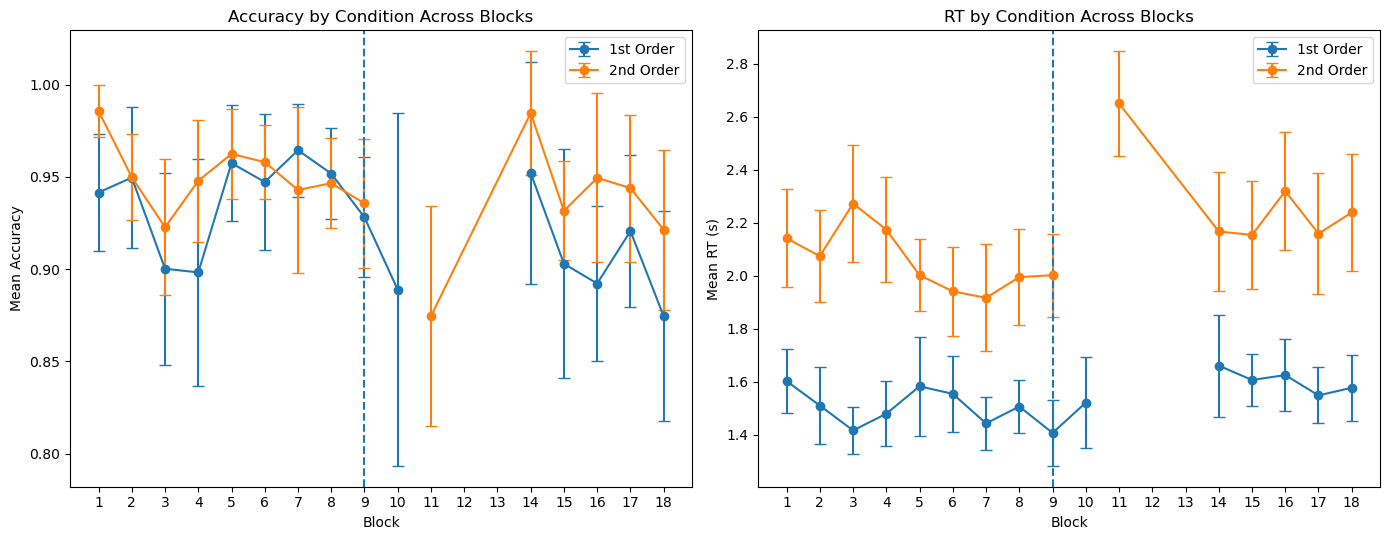

C:\Users\pkell\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\pkell\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\pkell\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 425.734761
  warnings.warn(msg, ConvergenceWarning)
C:\Users\pkell\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\pkell\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at t


Piecewise Mixed Model (Accuracy) — Overall (both conditions)
           Mixed Linear Model Regression Results
Model:              MixedLM   Dependent Variable:   y       
No. Observations:   1134      Method:               REML    
No. Groups:         79        Scale:                0.0160  
Min. group size:    12        Log-Likelihood:       510.7093
Max. group size:    16        Converged:            No      
Mean group size:    14.4                                    
------------------------------------------------------------
                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------
const              0.950    0.011 84.557 0.000  0.928  0.972
early             -0.002    0.004 -0.494 0.621 -0.009  0.005
late              -0.003    0.003 -0.853 0.394 -0.009  0.004
const Var          0.002                                    
const x early Cov -0.001                                    
early Var          0.001           

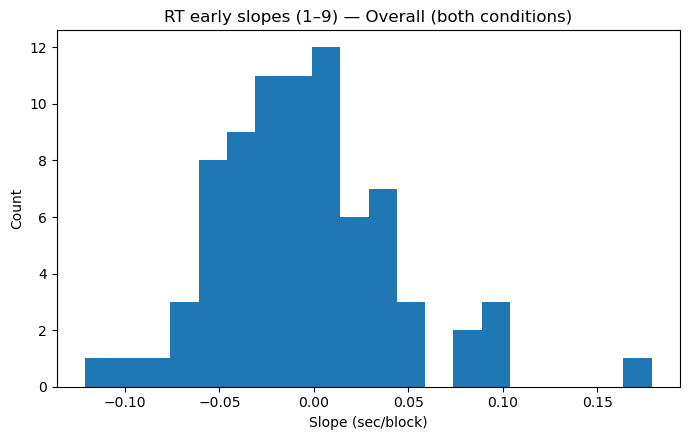

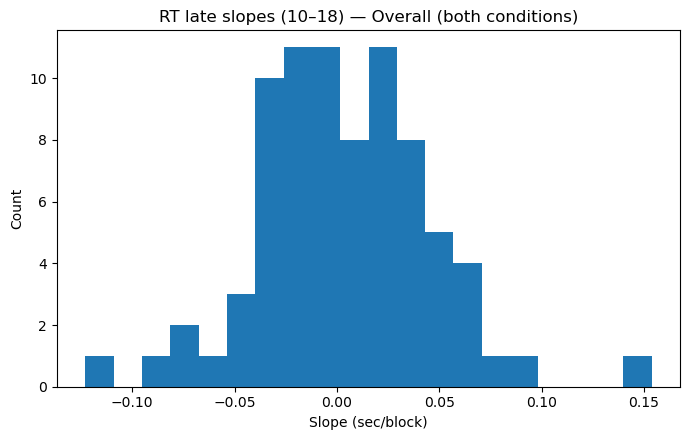

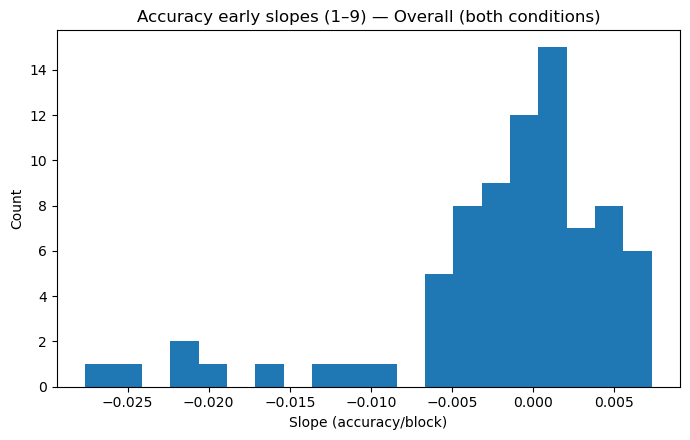

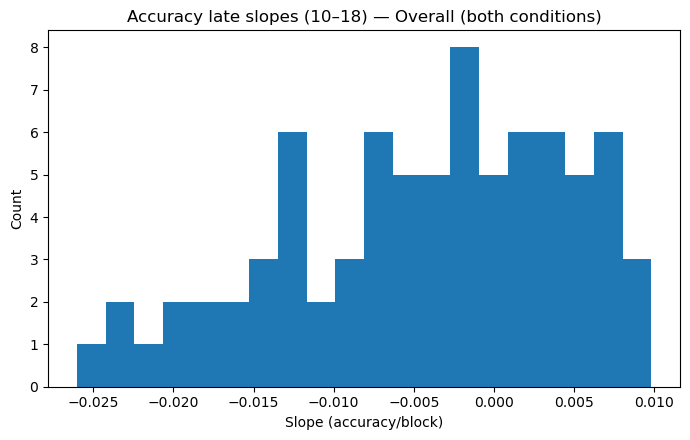

C:\Users\pkell\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\pkell\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\pkell\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 286.332608
  warnings.warn(msg, ConvergenceWarning)
C:\Users\pkell\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\pkell\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at t


Piecewise Mixed Model (Accuracy) — Condition 1 (1st Order)
           Mixed Linear Model Regression Results
Model:               MixedLM   Dependent Variable:   y      
No. Observations:    569       Method:               REML   
No. Groups:          79        Scale:                0.0191 
Min. group size:     5         Log-Likelihood:       92.8574
Max. group size:     10        Converged:            No     
Mean group size:     7.2                                    
------------------------------------------------------------
                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------
const              0.926    0.021 44.002 0.000  0.885  0.968
early              0.001    0.006  0.139 0.889 -0.011  0.013
late              -0.004    0.005 -0.902 0.367 -0.014  0.005
const Var          0.012    0.076                           
const x early Cov -0.003    0.009                           
early Var          0.002             

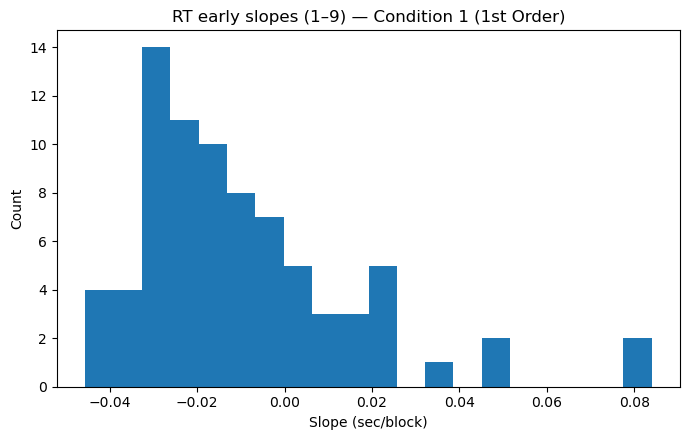

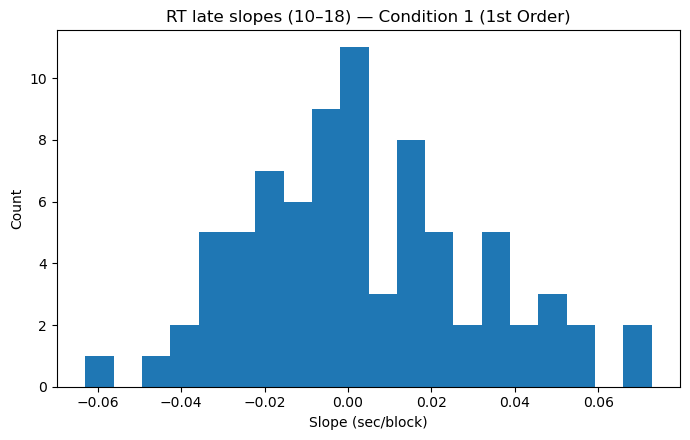

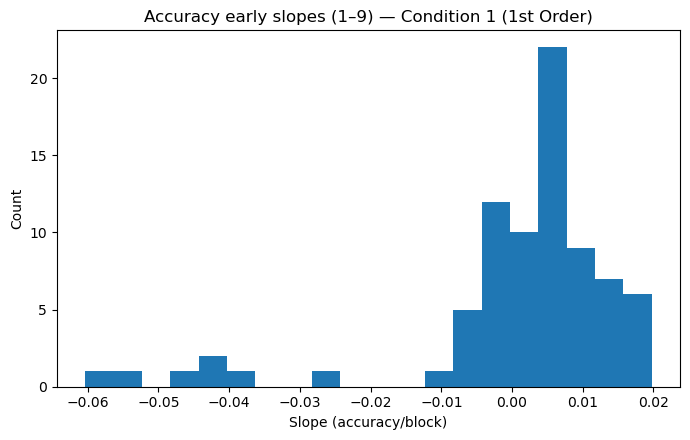

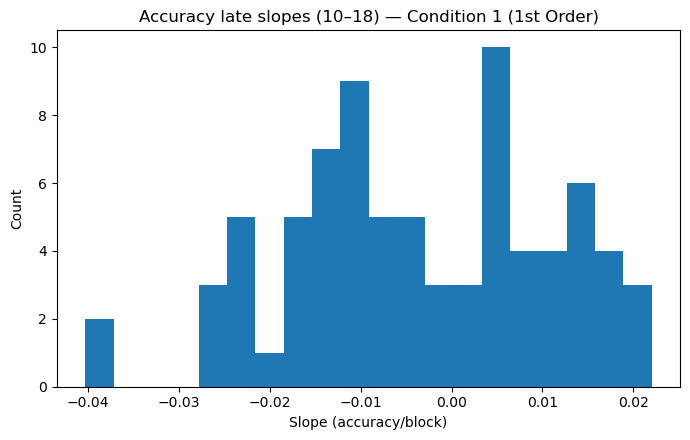

C:\Users\pkell\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\pkell\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\pkell\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 285.965946
  warnings.warn(msg, ConvergenceWarning)
C:\Users\pkell\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\pkell\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at t


Piecewise Mixed Model (Accuracy) — Condition 2 (2nd Order)
           Mixed Linear Model Regression Results
Model:              MixedLM   Dependent Variable:   y       
No. Observations:   565       Method:               REML    
No. Groups:         79        Scale:                0.0085  
Min. group size:    5         Log-Likelihood:       344.9405
Max. group size:    9         Converged:            No      
Mean group size:    7.2                                     
------------------------------------------------------------
                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------
const              0.969    0.012 80.856 0.000  0.946  0.993
early             -0.004    0.004 -1.036 0.300 -0.012  0.004
late               0.001    0.003  0.191 0.849 -0.005  0.006
const Var          0.003                                    
const x early Cov -0.001                                    
early Var          0.001             

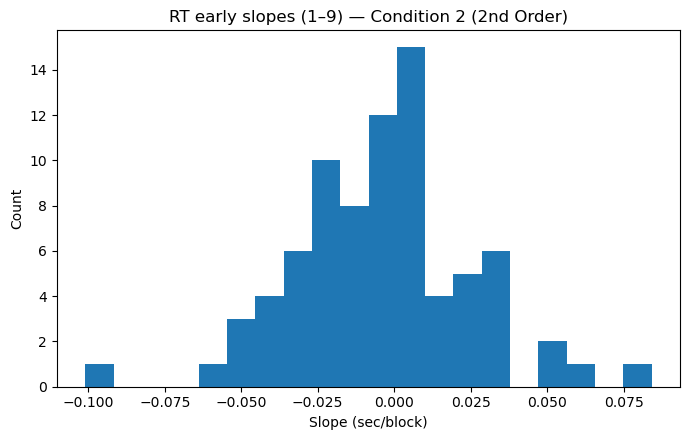

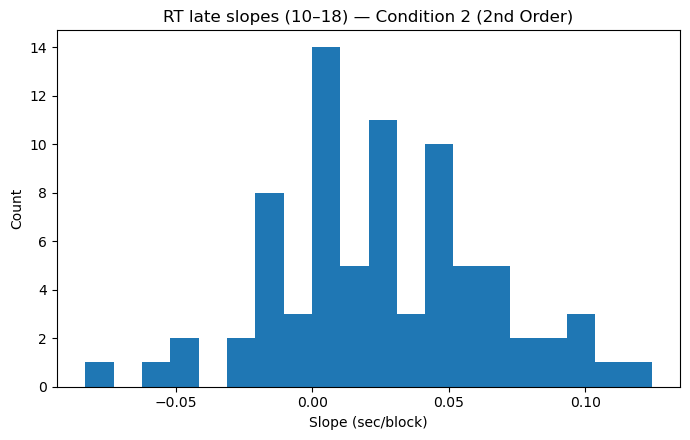

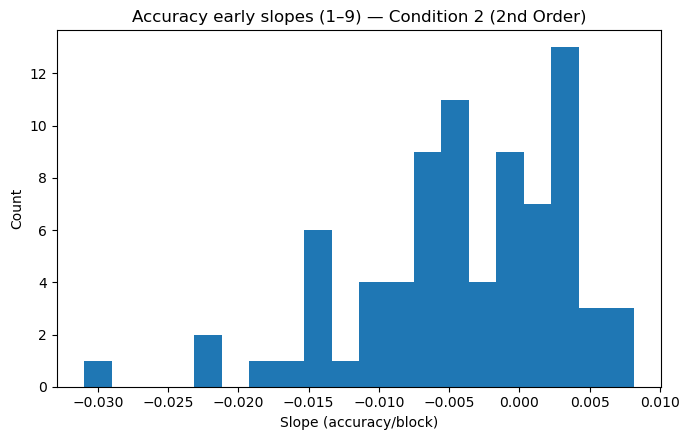

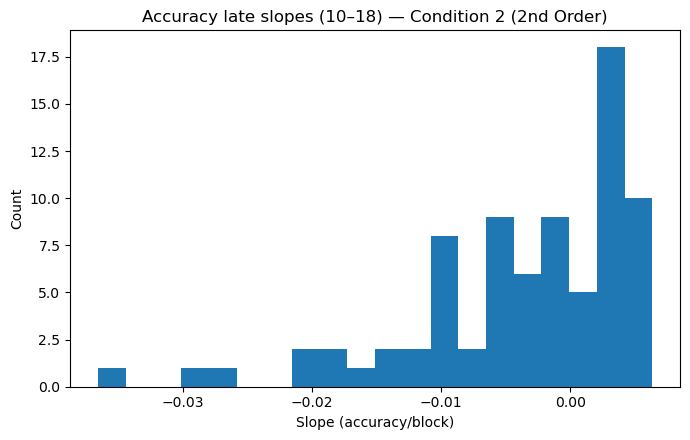


Change-point summary — Overall (both conditions)
RT change-point counts:
CP_RT
3      5
4      4
5      8
6      2
7      7
8      3
9     17
10    15
14     3
15     9
16     6
Name: count, dtype: int64

Accuracy change-point counts:
CP_Acc
3     11
4      9
5      3
6      1
7      3
8      4
9      7
10     5
11     2
14     5
15    12
16    17
Name: count, dtype: int64


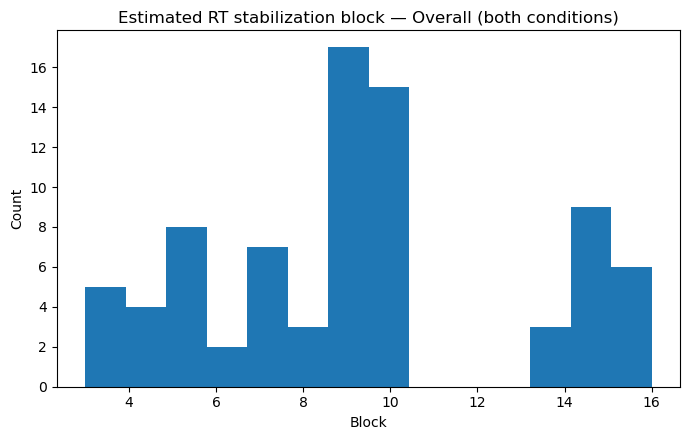

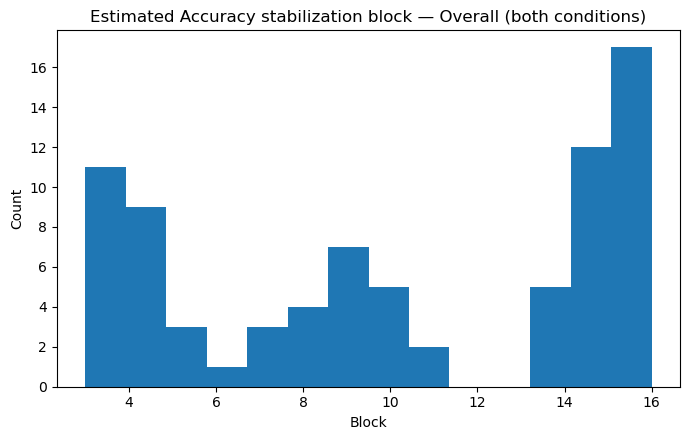


Change-point summary — Condition 1 (1st Order)
RT change-point counts:
CP_RT
3.0     13
4.0      6
5.0      6
6.0      8
7.0      9
8.0      8
9.0      5
10.0    14
14.0     2
15.0     4
16.0     3
Name: count, dtype: int64

Accuracy change-point counts:
CP_Acc
3.0     14
4.0      4
5.0      9
6.0      5
7.0      6
8.0      8
9.0      6
10.0    12
14.0     2
15.0     8
16.0     4
Name: count, dtype: int64


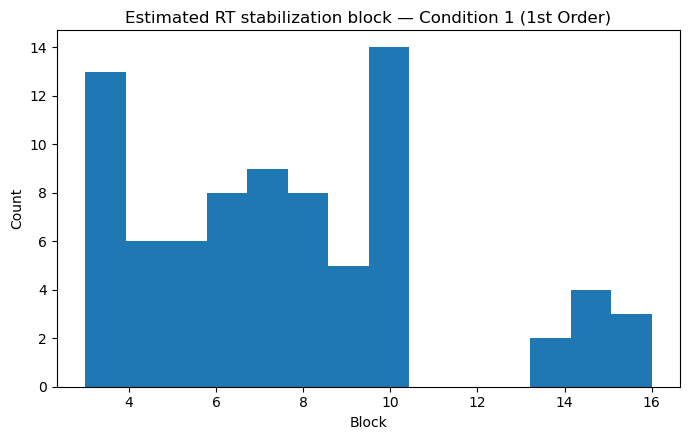

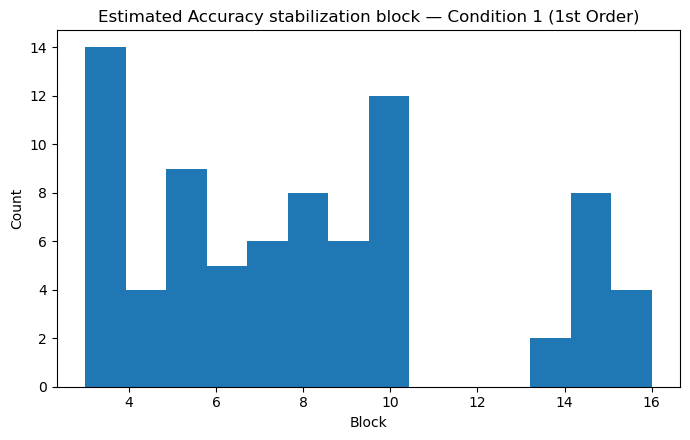


Change-point summary — Condition 2 (2nd Order)
RT change-point counts:
CP_RT
3      5
4     10
5      7
6      6
7      9
8      7
9     23
11     2
15     4
16     1
Name: count, dtype: int64

Accuracy change-point counts:
CP_Acc
3      7
4      5
5      6
6     10
7      9
8      8
9     16
11     4
14     1
15     6
16     2
Name: count, dtype: int64


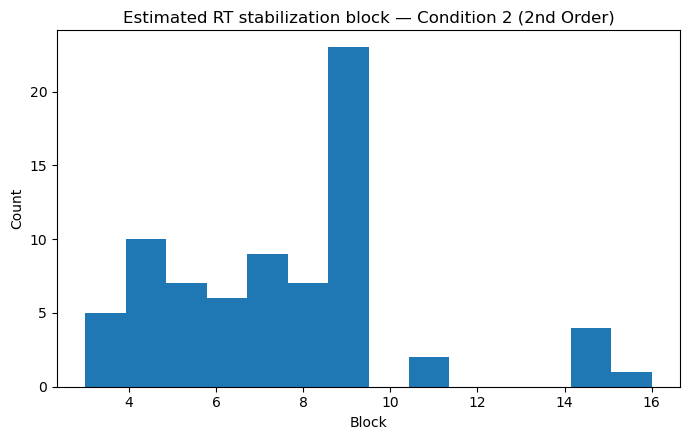

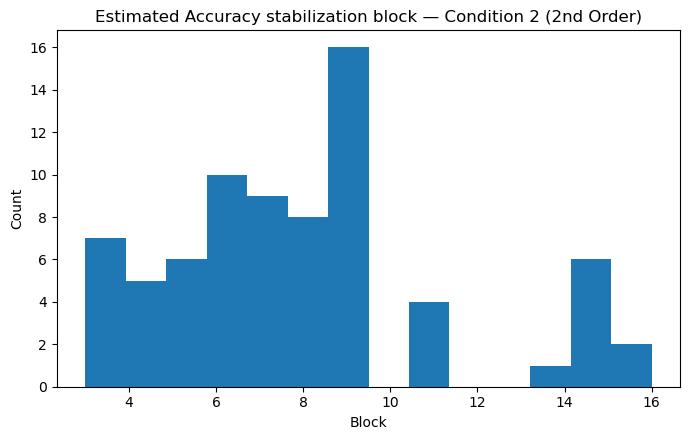


Saved outputs to: C:\Users\pkell\behavior_learning_outputs


In [11]:
# ============================================================
# DROP-IN (UPDATED): Quantify "learning/adjustment" during first ~9 blocks
#   - Uses your *actual* PsychoPy column names from your old code:
#       Condition:        'cond'              (1=1st order, 2=2nd order)
#       Accuracy (trial): 'key_resp_2.corr'   (0/1)
#       RT (trial):       'key_resp_2.rt'     (sec)
#       Time (optional):  'thisRow.t'
#   - Adds clear plots:
#       (A) Block-wise group mean accuracy + CI (by condition)
#       (B) Block-wise group mean RT + CI (by condition)
#       (C) Piecewise mixed-model participant slope histograms (overall + by condition)
#       (D) Optional: participant "change-point" distributions (overall + by condition)
#
#   - Fits participant-level piecewise mixed-effects models with knot at block 9:
#       early slope (blocks 1–9), late slope (blocks 10–18)
#   - Computes "learning consistency" across participants:
#       RT learning: early slope < 0
#       Accuracy learning: early slope > 0
#
# REQUIREMENTS:
#   pip install pandas numpy matplotlib statsmodels scipy
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import statsmodels.api as sm
from statsmodels.regression.mixed_linear_model import MixedLM

# -----------------------------
# USER SETTINGS
# -----------------------------
DATA_DIR = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\behavioral data\data"
FILE_GLOB = os.path.join(DATA_DIR, "*.csv")

KNOT_BLOCK = 9
N_BLOCKS_EXPECTED = 18

# If your RT is already in seconds (PsychoPy typical), keep False
RT_IN_MS = False
USE_LOG_RT = False

# Drop blocks for a participant if too few trials
MIN_TRIALS_PER_BLOCK = 5

# Change-point settings
DO_CHANGEPOINT = True
CP_MIN_BLOCK = 3
CP_MAX_BLOCK = 16

# Condition labels (from your old code)
COND_LABELS = {1: "1st Order", 2: "2nd Order"}

# -----------------------------
# HELPERS
# -----------------------------
def piecewise_terms(block_series, knot=9):
    b = block_series.astype(float)
    early = np.minimum(b, knot)
    late  = np.maximum(0.0, b - knot)
    return early, late

def fit_mixed_piecewise(df_long, y_col, knot=9):
    """
    Mixed model:
      y ~ 1 + early + late
    Random effects by Subject:
      intercept + early + late
    """
    df = df_long.copy()
    df["early"], df["late"] = piecewise_terms(df["Block"], knot=knot)

    y = df[y_col].astype(float).values
    exog = sm.add_constant(df[["early", "late"]].astype(float))
    exog_re = sm.add_constant(df[["early", "late"]].astype(float))

    model = MixedLM(endog=y, exog=exog, groups=df["Subject"], exog_re=exog_re)
    res = model.fit(reml=True, method="lbfgs", maxiter=2000, disp=False)
    return res, df

def extract_subject_slopes(res):
    """
    Returns subject-specific early slope and late slope.
    late slope is post-knot slope (early + late increment).
    """
    fe = res.fe_params  # const, early, late
    subjects, early_s, late_s = [], [], []

    for sid, re_vec in res.random_effects.items():
        re_arr = np.asarray(re_vec)
        if re_arr.shape[0] < 3:
            raise RuntimeError("Unexpected random effects length; expected 3 (intercept, early, late).")
        re_early, re_late = re_arr[1], re_arr[2]
        subjects.append(str(sid))
        early_s.append(fe["early"] + re_early)
        late_s.append((fe["early"] + fe["late"]) + (re_early + re_late))

    return pd.DataFrame({"Subject": subjects, "Slope_Early": early_s, "Slope_Late": late_s})

def hist(series, title, xlabel, bins=20):
    s = pd.to_numeric(series, errors="coerce").dropna().astype(float)
    plt.figure(figsize=(7, 4.5))
    plt.hist(s, bins=bins)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

def simple_changepoint_sse(x, y, min_cp=3, max_cp=16):
    x = np.asarray(x).astype(float)
    y = np.asarray(y).astype(float)
    sse_by_cp = {}
    for cp in range(min_cp, max_cp + 1):
        m1 = x <= cp
        m2 = x > cp
        if m1.sum() < 2 or m2.sum() < 2:
            continue
        X1 = sm.add_constant(x[m1])
        b1 = np.linalg.lstsq(X1, y[m1], rcond=None)[0]
        yhat1 = X1 @ b1
        X2 = sm.add_constant(x[m2])
        b2 = np.linalg.lstsq(X2, y[m2], rcond=None)[0]
        yhat2 = X2 @ b2
        sse_by_cp[cp] = np.sum((y[m1] - yhat1) ** 2) + np.sum((y[m2] - yhat2) ** 2)
    if not sse_by_cp:
        return np.nan, {}
    best_cp = min(sse_by_cp, key=sse_by_cp.get)
    return best_cp, sse_by_cp

def mean_ci95(x):
    x = pd.to_numeric(x, errors="coerce").dropna().astype(float)
    n = x.shape[0]
    if n <= 1:
        return np.nan, np.nan
    m = x.mean()
    se = stats.sem(x, nan_policy="omit")
    ci = se * stats.t.ppf(0.975, n - 1)
    return m, ci

# -----------------------------
# LOAD + COMBINE (your PsychoPy format)
# -----------------------------
files = sorted(glob.glob(FILE_GLOB))
files = [f for f in files if os.path.isfile(f)]
if len(files) == 0:
    raise FileNotFoundError(f"No CSV files found: {FILE_GLOB}")

all_data = []
for f in files:
    df = pd.read_csv(f)

    # Identify participant the same way as your old code
    df["Subject"] = os.path.splitext(os.path.basename(f))[0]

    all_data.append(df)

raw = pd.concat(all_data, ignore_index=True)

# -----------------------------
# USE YOUR KNOWN COLUMNS
# -----------------------------
# Required columns from your old code:
REQUIRED = ["cond", "key_resp_2.corr", "key_resp_2.rt"]
missing = [c for c in REQUIRED if c not in raw.columns]
if missing:
    raise ValueError(
        f"Missing expected columns {missing}.\n"
        f"Columns present: {list(raw.columns)}\n"
        f"If your column names differ, tell me what they are and I’ll adapt the script."
    )

raw["cond"] = pd.to_numeric(raw["cond"], errors="coerce")
raw["Accuracy"] = pd.to_numeric(raw["key_resp_2.corr"], errors="coerce")
raw["RT"] = pd.to_numeric(raw["key_resp_2.rt"], errors="coerce")

# Convert RT if needed
if RT_IN_MS:
    raw["RT"] = raw["RT"] / 1000.0

# ------------------------------------------------------------
# CREATE Block index (1..18) from the trial stream
#   Your old "row_cutoffs" method pooled across participants and
#   used cumulative slicing, but for learning we need per-subject blocks.
#
#   PsychoPy exports typically contain one row per trial and you
#   can recover blocks by counting trials within a participant,
#   then mapping to 18 blocks.
#
#   We try two strategies:
#     1) If a 'block' column exists, use it.
#     2) Else infer blocks using trial index and expected trials per block.
#
#   In your old mapping, block1 ended at row 42 and block2 at 49, etc.
#   This implies block sizes vary slightly. Without explicit block markers,
#   we cannot perfectly reconstruct blocks. So:
#     - We look for common PsychoPy columns first (e.g., 'block', 'Block', 'blocks.thisN')
#     - If none exist, we infer blocks by splitting each participant's
#       trials into 18 consecutive chunks with near-equal sizes.
# ------------------------------------------------------------
block_cols = [c for c in raw.columns if c.lower() in ["block", "blocks", "blocknum", "block_number", "blk"]]
if len(block_cols) > 0:
    blk_col = block_cols[0]
    raw["Block"] = pd.to_numeric(raw[blk_col], errors="coerce")
else:
    # Infer blocks per participant by splitting trial index into 18 chunks
    raw = raw.sort_values(["Subject"]).copy()
    raw["__trial_index__"] = raw.groupby("Subject").cumcount()  # 0..(n_trials-1)

    def infer_block_ids(trial_idx, n_blocks=18):
        # Assign approximately equal-sized blocks
        n = len(trial_idx)
        # boundaries in trial-index space
        edges = np.linspace(0, n, n_blocks + 1)
        # block is 1..n_blocks
        # For each trial index i, find which bin it falls into
        return np.clip(np.digitize(trial_idx, edges[1:-1], right=False) + 1, 1, n_blocks)

    raw["Block"] = raw.groupby("Subject")["__trial_index__"].transform(lambda s: infer_block_ids(s.values, N_BLOCKS_EXPECTED))

# Keep only valid blocks
raw["Block"] = pd.to_numeric(raw["Block"], errors="coerce")
raw = raw.dropna(subset=["Subject", "Block", "cond"])
raw["Block"] = raw["Block"].astype(int)
raw = raw[(raw["Block"] >= 1) & (raw["Block"] <= N_BLOCKS_EXPECTED)]

# -----------------------------
# AGGREGATE to Subject × Block × Condition
# -----------------------------
agg = (
    raw.groupby(["Subject", "Block", "cond"], as_index=False)
       .agg(
           Acc_Mean=("Accuracy", "mean"),
           RT_Mean=("RT", "mean"),
           n_trials=("Accuracy", "size")
       )
)

# Drop sparse blocks
agg = agg[agg["n_trials"] >= MIN_TRIALS_PER_BLOCK].copy()

# Optional log RT
if USE_LOG_RT:
    agg["RT_Model"] = np.log(np.clip(agg["RT_Mean"].astype(float), 1e-6, None))
else:
    agg["RT_Model"] = agg["RT_Mean"].astype(float)

# -----------------------------
# PLOT 1–2: Block-wise group mean curves (by condition)
# -----------------------------
# Compute mean + CI95 across participants for each Block × cond
summ_rows = []
for (blk, cond), d in agg.groupby(["Block", "cond"]):
    acc_m, acc_ci = mean_ci95(d["Acc_Mean"])
    rt_m, rt_ci = mean_ci95(d["RT_Mean"])
    summ_rows.append({
        "Block": blk,
        "cond": int(cond),
        "Acc_Mean": acc_m,
        "Acc_CI95": acc_ci,
        "RT_Mean": rt_m,
        "RT_CI95": rt_ci,
        "n_subject_blocks": d["Subject"].nunique()
    })
summ = pd.DataFrame(summ_rows).sort_values(["cond", "Block"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Accuracy
for cond in sorted(summ["cond"].unique()):
    d = summ[summ["cond"] == cond]
    axes[0].errorbar(d["Block"], d["Acc_Mean"], yerr=d["Acc_CI95"], marker="o", capsize=4,
                     label=COND_LABELS.get(cond, str(cond)))
axes[0].axvline(KNOT_BLOCK, linestyle="--")
axes[0].set_title("Accuracy by Condition Across Blocks")
axes[0].set_xlabel("Block")
axes[0].set_ylabel("Mean Accuracy")
axes[0].set_xticks(list(range(1, N_BLOCKS_EXPECTED + 1)))
axes[0].legend()
axes[0].grid(False)

# RT
for cond in sorted(summ["cond"].unique()):
    d = summ[summ["cond"] == cond]
    axes[1].errorbar(d["Block"], d["RT_Mean"], yerr=d["RT_CI95"], marker="o", capsize=4,
                     label=COND_LABELS.get(cond, str(cond)))
axes[1].axvline(KNOT_BLOCK, linestyle="--")
axes[1].set_title("RT by Condition Across Blocks")
axes[1].set_xlabel("Block")
axes[1].set_ylabel("Mean RT (s)")
axes[1].set_xticks(list(range(1, N_BLOCKS_EXPECTED + 1)))
axes[1].legend()
axes[1].grid(False)

plt.tight_layout()
plt.show()

# -----------------------------
# FIT PIECEWISE MIXED MODELS (overall + by condition)
# -----------------------------
def run_models_for_subset(df_subset, label):
    """
    df_subset must have columns: Subject, Block, Acc_Mean, RT_Model
    """
    df_subset = df_subset.copy()
    df_subset["Subject"] = df_subset["Subject"].astype(str)
    df_subset["Block"] = pd.to_numeric(df_subset["Block"], errors="coerce")

    # Accuracy model
    acc_df = df_subset.dropna(subset=["Acc_Mean"])[["Subject","Block","Acc_Mean"]].rename(columns={"Acc_Mean":"Y"})
    rt_df  = df_subset.dropna(subset=["RT_Model"])[["Subject","Block","RT_Model"]].rename(columns={"RT_Model":"Y"})

    acc_res, _ = fit_mixed_piecewise(acc_df, y_col="Y", knot=KNOT_BLOCK)
    rt_res,  _ = fit_mixed_piecewise(rt_df,  y_col="Y", knot=KNOT_BLOCK)

    print("\n==============================")
    print(f"Piecewise Mixed Model (Accuracy) — {label}")
    print("==============================")
    print(acc_res.summary())

    print("\n==============================")
    print(f"Piecewise Mixed Model (RT{' log' if USE_LOG_RT else ''}) — {label}")
    print("==============================")
    print(rt_res.summary())

    acc_slopes = extract_subject_slopes(acc_res).rename(columns={"Slope_Early":"AccSlope_Early","Slope_Late":"AccSlope_Late"})
    rt_slopes  = extract_subject_slopes(rt_res).rename(columns={"Slope_Early":"RTSlope_Early","Slope_Late":"RTSlope_Late"})
    slopes = acc_slopes.merge(rt_slopes, on="Subject", how="outer")

    # Learning proportions
    rt_prop  = np.mean(pd.to_numeric(slopes["RTSlope_Early"], errors="coerce").dropna() < 0) if slopes["RTSlope_Early"].notna().any() else np.nan
    acc_prop = np.mean(pd.to_numeric(slopes["AccSlope_Early"], errors="coerce").dropna() > 0) if slopes["AccSlope_Early"].notna().any() else np.nan

    print("\nParticipant-level 'learning/adjustment' proportions")
    print(f"  RT: proportion with negative early slope (1–{KNOT_BLOCK})  = {rt_prop:.3f}")
    print(f"  Acc: proportion with positive early slope (1–{KNOT_BLOCK}) = {acc_prop:.3f}")

    # Plots
    hist(slopes["RTSlope_Early"],  f"RT early slopes (1–{KNOT_BLOCK}) — {label}",  "Slope (sec/block)" + (" [log]" if USE_LOG_RT else ""))
    hist(slopes["RTSlope_Late"],   f"RT late slopes ({KNOT_BLOCK+1}–{N_BLOCKS_EXPECTED}) — {label}", "Slope (sec/block)" + (" [log]" if USE_LOG_RT else ""))
    hist(slopes["AccSlope_Early"], f"Accuracy early slopes (1–{KNOT_BLOCK}) — {label}", "Slope (accuracy/block)")
    hist(slopes["AccSlope_Late"],  f"Accuracy late slopes ({KNOT_BLOCK+1}–{N_BLOCKS_EXPECTED}) — {label}", "Slope (accuracy/block)")

    return slopes

# Overall (pool both conditions; weighted equally at block level)
overall_df = agg.groupby(["Subject","Block"], as_index=False).agg(
    Acc_Mean=("Acc_Mean", "mean"),
    RT_Mean=("RT_Mean", "mean"),
    RT_Model=("RT_Model", "mean"),
    n_trials=("n_trials", "sum")
)
slopes_overall = run_models_for_subset(overall_df, "Overall (both conditions)")

# By condition
slopes_by_cond = {}
for cond in sorted(agg["cond"].unique()):
    df_c = agg[agg["cond"] == cond].copy()
    slopes_by_cond[int(cond)] = run_models_for_subset(df_c, f"Condition {int(cond)} ({COND_LABELS.get(int(cond), '')})")

# -----------------------------
# OPTIONAL: Change-point per subject (overall + by condition)
# -----------------------------
if DO_CHANGEPOINT:
    def run_changepoints(df_subset, label):
        rows = []
        for sid, d in df_subset.groupby("Subject"):
            d = d.sort_values("Block")
            if d["Block"].nunique() < 6:
                continue

            # RT
            rt_d = d.dropna(subset=["RT_Model"])
            acc_d = d.dropna(subset=["Acc_Mean"])

            cp_rt, _ = (np.nan, {})
            cp_acc, _ = (np.nan, {})

            if rt_d["Block"].nunique() >= 6:
                cp_rt, _ = simple_changepoint_sse(rt_d["Block"].values, rt_d["RT_Model"].values,
                                                  min_cp=CP_MIN_BLOCK, max_cp=CP_MAX_BLOCK)
            if acc_d["Block"].nunique() >= 6:
                cp_acc, _ = simple_changepoint_sse(acc_d["Block"].values, acc_d["Acc_Mean"].values,
                                                   min_cp=CP_MIN_BLOCK, max_cp=CP_MAX_BLOCK)

            rows.append({"Subject": str(sid), "CP_RT": cp_rt, "CP_Acc": cp_acc})

        cp_df = pd.DataFrame(rows)
        print("\n==============================")
        print(f"Change-point summary — {label}")
        print("==============================")
        if len(cp_df) == 0:
            print("No subjects had sufficient data for change-point estimation.")
            return cp_df

        print("RT change-point counts:")
        print(cp_df["CP_RT"].value_counts(dropna=True).sort_index())
        print("\nAccuracy change-point counts:")
        print(cp_df["CP_Acc"].value_counts(dropna=True).sort_index())

        hist(cp_df["CP_RT"].dropna(),  f"Estimated RT stabilization block — {label}",  "Block", bins=14)
        hist(cp_df["CP_Acc"].dropna(), f"Estimated Accuracy stabilization block — {label}", "Block", bins=14)
        return cp_df

    cp_overall = run_changepoints(overall_df, "Overall (both conditions)")
    cp_by_cond = {}
    for cond in sorted(agg["cond"].unique()):
        cp_by_cond[int(cond)] = run_changepoints(agg[agg["cond"] == cond], f"Condition {int(cond)} ({COND_LABELS.get(int(cond), '')})")

# -----------------------------
# SAVE OUTPUTS
# -----------------------------
out_dir = "./behavior_learning_outputs"
os.makedirs(out_dir, exist_ok=True)

raw.to_csv(os.path.join(out_dir, "behavior_raw_combined.csv"), index=False)
agg.to_csv(os.path.join(out_dir, "behavior_block_means_bycond.csv"), index=False)
summ.to_csv(os.path.join(out_dir, "behavior_group_curves_bycond.csv"), index=False)

slopes_overall.to_csv(os.path.join(out_dir, "participant_piecewise_slopes_overall.csv"), index=False)
for cond, df_s in slopes_by_cond.items():
    df_s.to_csv(os.path.join(out_dir, f"participant_piecewise_slopes_cond{cond}.csv"), index=False)

if DO_CHANGEPOINT and "cp_overall" in locals():
    cp_overall.to_csv(os.path.join(out_dir, "participant_change_points_overall.csv"), index=False)
    for cond, df_cp in (cp_by_cond or {}).items():
        df_cp.to_csv(os.path.join(out_dir, f"participant_change_points_cond{cond}.csv"), index=False)

print(f"\nSaved outputs to: {os.path.abspath(out_dir)}")

# -----------------------------
# NOTE (IMPORTANT):
# If your CSVs contain a true block column (common in PsychoPy exports),
# the script will use it. If not, it will infer blocks by splitting each
# participant's trial stream into 18 equal-ish chunks.
#
# If you want exact block assignment, tell me what column in your CSV
# encodes block number (or share a header row), and I’ll update the script
# to use it explicitly.
# -----------------------------